# BrewScope — Stage 7: Modeling Multinomial Naive Bayes (MNB)

Notebook ini berisi **section MNB** untuk dua task ABSA:

- **Task A** — deteksi aspek (multi-label, 6 aspek) pada tingkat review.
- **Task B** — klasifikasi sentimen per aspek (`negative` / `neutral` / `positive`).

Notebook yang sama akan dilanjutkan oleh rekan SVM dan Random Forest dengan menambah section baru **di bawah** section MNB. Jangan rename file ini setelah di-push.

**Catatan penting:** label pada dataset adalah *pseudo-label* (`auto:lexical_preannotation_v1`), bukan human gold. Semua angka evaluasi di notebook ini adalah performa terhadap pseudo-label tersebut.

Aturan yang dipatuhi (lihat `docs/modeling/mnb_handoff_guide.md`):

1. Split dipakai apa adanya dari kolom `split`; tidak ada split baru.
2. `TfidfVectorizer` hanya di-fit pada baris `train`.
3. Hyperparameter (`alpha`) hanya dipilih memakai `validation`.
4. `test` dievaluasi **satu kali**, setelah tuning selesai.
5. Varian teks yang dipakai: `text_clean`.

## 0. Persiapan environment

Jalankan dari root repo (PowerShell):

    .\.venv\Scripts\Activate.ps1
    python -m pip install -e ".[preprocessing,modeling]"

In [1]:
from __future__ import annotations

import hashlib
import json
import platform
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300})

AUTHOR = "Nik"  # nama pengerja section MNB (dicatat di manifest)
TEXT_VARIANT = "text_clean"
SPLITS = ["train", "validation", "test"]
ASPECTS = [
    "product_quality",
    "service",
    "price_value",
    "ambience",
    "facilities",
    "cleanliness",
]
ASPECT_LABEL_COLUMNS = [f"aspect_{aspect}" for aspect in ASPECTS]
SENTIMENTS = ["negative", "neutral", "positive"]

# Konfigurasi TF-IDF baseline: seragam untuk MNB, SVM, dan Random Forest.
TFIDF_PARAMS = {
    "sublinear_tf": True,
    "min_df": 2,
    "ngram_range": (1, 2),
    "max_features": 10_000,
}
ALPHA_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 0.5, 1.0, 2.0]
DEFAULT_ALPHA = 1.0

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Root proyek tidak ditemukan. Jalankan dari root repo atau notebooks/.")

SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "modeling" / "splits"
TASK_A_INPUT = SPLIT_DIR / "aspect_detection_with_split.csv"
TASK_B_INPUT = SPLIT_DIR / "aspect_sentiment_with_split.csv"
SPLIT_MANIFEST = SPLIT_DIR / "split_manifest.json"

TABLES_DIR = PROJECT_ROOT / "reports" / "tables" / "modeling" / "mnb"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures" / "modeling" / "mnb"
ARTIFACT_DIR = PROJECT_ROOT / "data" / "processed" / "modeling" / "mnb"
A_DIR = ARTIFACT_DIR / "task_a"
B_DIR = ARTIFACT_DIR / "task_b"
for directory in (TABLES_DIR, FIGURES_DIR, A_DIR, B_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("python      :", platform.python_version())
if sklearn.__version__ != "1.9.1":
    print("PERINGATAN: target handoff adalah scikit-learn 1.9.1; diskusikan sebelum menyimpan artefak.")

scikit-learn: 1.9.1
pandas      : 2.3.3
numpy       : 2.4.6
python      : 3.11.9


## 1. Memuat dan memvalidasi data split

Kedua file sudah memuat kolom `split` final. Notebook ini hanya membaca, tidak membuat ulang split. Validasi di bawah memastikan: nilai `split` valid, tidak ada `duplicate_group_id` yang terbagi ke lebih dari satu split, split Task A dan Task B konsisten per review, dan teks model tidak kosong.

In [2]:
task_a = pd.read_csv(TASK_A_INPUT, encoding="utf-8-sig", keep_default_na=False)
task_b = pd.read_csv(TASK_B_INPUT, encoding="utf-8-sig", keep_default_na=False)

required_a = {"review_id", "duplicate_group_id", "split", TEXT_VARIANT, *ASPECT_LABEL_COLUMNS}
required_b = {
    "annotation_id", "review_id", "duplicate_group_id", "aspect_category",
    "sentiment", "split", TEXT_VARIANT, "aspect_text_model",
}
missing_a = sorted(required_a - set(task_a.columns))
missing_b = sorted(required_b - set(task_b.columns))
if missing_a or missing_b:
    raise ValueError(f"Kolom hilang. Task A: {missing_a}; Task B: {missing_b}")

assert set(task_a["split"]) == set(SPLITS), "Nilai split Task A tidak valid"
assert set(task_b["split"]) == set(SPLITS), "Nilai split Task B tidak valid"
assert set(task_b["aspect_category"]) == set(ASPECTS), "aspect_category tidak sesuai"
assert set(task_b["sentiment"]) == set(SENTIMENTS), "Label sentimen tidak sesuai"
assert task_a["review_id"].is_unique and task_b["annotation_id"].is_unique

# Tidak ada group duplikat yang terbelah antar split.
for name, frame in (("Task A", task_a), ("Task B", task_b)):
    splits_per_group = frame.groupby("duplicate_group_id")["split"].nunique()
    assert (splits_per_group == 1).all(), f"Group leakage terdeteksi di {name}"

# Review yang sama harus berada di split yang sama pada Task A dan Task B.
split_a = task_a.set_index("review_id")["split"]
split_b = task_b.drop_duplicates("review_id").set_index("review_id")["split"]
assert (split_a.reindex(split_b.index) == split_b).all(), "Split A dan B tidak konsisten"

for frame, column in ((task_a, TEXT_VARIANT), (task_b, TEXT_VARIANT), (task_b, "aspect_text_model")):
    assert (frame[column].str.strip() != "").all(), f"Ada teks kosong di {column}"

print("Validasi struktur dan leakage: OK")
summary = pd.DataFrame({
    "Task A (review)": task_a["split"].value_counts(),
    "Task B (review-aspek)": task_b["split"].value_counts(),
}).reindex(SPLITS)
display(summary)

Validasi struktur dan leakage: OK


,Task A (review),Task B (review-aspek)
split,,
train,2396,3313
validation,514,1143
test,514,1142


### 1.1 Verifikasi hash file split

Panduan mewajibkan hash input split cocok dengan `split_manifest.json`. Hash di manifest dihitung pada file dengan line ending **CRLF** (dibuat di Windows), sedangkan checkout Git/ZIP bisa berisi **LF**. Isi data identik, hanya byte newline yang berbeda. Karena itu hash dicek dalam dua bentuk: apa adanya (`raw`) dan setelah dinormalisasi ke CRLF.

In [3]:
def sha256_file(path: Path, normalize_crlf: bool = False) -> str:
    data = Path(path).read_bytes()
    if normalize_crlf:
        data = data.replace(b"\r\n", b"\n").replace(b"\n", b"\r\n")
    return hashlib.sha256(data).hexdigest()


split_manifest = json.loads(SPLIT_MANIFEST.read_text(encoding="utf-8"))
expected_hashes = {
    key.replace("\\", "/"): value["sha256"]
    for key, value in split_manifest["outputs"].items()
}

input_hashes = {}
for path in (TASK_A_INPUT, TASK_B_INPUT):
    relative = path.relative_to(PROJECT_ROOT).as_posix()
    raw_hash = sha256_file(path)
    crlf_hash = sha256_file(path, normalize_crlf=True)
    expected = expected_hashes[relative]
    if raw_hash == expected:
        status = "match"
    elif crlf_hash == expected:
        status = "match_after_crlf_normalization"
    else:
        status = "MISMATCH"
    input_hashes[relative] = {
        "sha256_raw": raw_hash,
        "sha256_crlf_normalized": crlf_hash,
        "expected_in_split_manifest": expected,
        "status": status,
    }

display(pd.DataFrame(input_hashes).T[["status", "expected_in_split_manifest"]])
assert all(item["status"] != "MISMATCH" for item in input_hashes.values()), (
    "Hash file split tidak cocok dengan split_manifest.json"
)
print("Hash input split cocok dengan split_manifest.json")

,status,expected_in_split_manifest
data/processed/modeling/splits/aspect_detection_with_split.csv,match,ad951d37f94154714cb95207000df0613295c999d1d911...
data/processed/modeling/splits/aspect_sentiment_with_split.csv,match,7c8fe622961a63afec668bb8b14710ca4eee2d6d088a6c...


Hash input split cocok dengan split_manifest.json


## 2. Fungsi bantu

In [4]:
def make_tfidf() -> TfidfVectorizer:
    """Vectorizer baru dengan konfigurasi baseline yang seragam."""
    return TfidfVectorizer(**TFIDF_PARAMS)


def pick_alpha(tuning: pd.DataFrame, metric: str) -> float:
    """Alpha dengan metrik validation tertinggi; seri -> yang terdekat ke 1.0."""
    ranked = tuning.assign(_dist=(tuning["alpha"] - DEFAULT_ALPHA).abs()).sort_values(
        [metric, "_dist"], ascending=[False, True]
    )
    return float(ranked.iloc[0]["alpha"])


def task_a_metrics(Y_true: np.ndarray, Y_pred: np.ndarray, split_name: str) -> pd.DataFrame:
    precision, recall, f1, support = precision_recall_fscore_support(
        Y_true, Y_pred, average=None, zero_division=0
    )
    rows = [
        {
            "aspect": aspect,
            "precision": precision[i],
            "recall": recall[i],
            "f1": f1[i],
            "support": int(support[i]),
            "split": split_name,
        }
        for i, aspect in enumerate(ASPECTS)
    ]
    for average in ("macro", "micro"):
        p, r, f, _ = precision_recall_fscore_support(
            Y_true, Y_pred, average=average, zero_division=0
        )
        rows.append({
            "aspect": f"{average} avg", "precision": p, "recall": r, "f1": f,
            "support": int(Y_true.sum()), "split": split_name,
        })
    return pd.DataFrame(rows)


def sentiment_metrics(y_true, y_pred) -> dict:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=SENTIMENTS, zero_division=0
    )
    return {
        "n_rows": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=SENTIMENTS, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=SENTIMENTS, average="weighted", zero_division=0),
        "recall_negative": recall[0],
        "precision_negative": precision[0],
        "f1_negative": f1[0],
        "f1_neutral": f1[1],
        "f1_positive": f1[2],
        "support_negative": int(support[0]),
        "support_neutral": int(support[1]),
        "support_positive": int(support[2]),
    }


def plot_confusion(ax, y_true, y_pred, title: str) -> None:
    matrix = confusion_matrix(y_true, y_pred, labels=SENTIMENTS)
    short = ["neg", "neu", "pos"]
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=short, yticklabels=short, ax=ax,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

## Task A — MNB

Satu baris = satu review; target = 6 kolom biner. Model: `OneVsRestClassifier(MultinomialNB(alpha=...))` di atas TF-IDF `text_clean`.

### A.1 TF-IDF (fit hanya pada train)

Vectorizer di-fit pada baris `train`, lalu dipakai untuk men-transform `validation` dan `test`.

In [5]:
A = {split: task_a[task_a["split"] == split].reset_index(drop=True) for split in SPLITS}
A_Y = {split: A[split][ASPECT_LABEL_COLUMNS].to_numpy(dtype=int) for split in SPLITS}

tfidf_a = make_tfidf()
A_X = {"train": tfidf_a.fit_transform(A["train"][TEXT_VARIANT])}   # fit: hanya train
A_X["validation"] = tfidf_a.transform(A["validation"][TEXT_VARIANT])
A_X["test"] = tfidf_a.transform(A["test"][TEXT_VARIANT])

assert A_X["train"].shape[0] == len(A["train"])
print("Ukuran kosakata:", len(tfidf_a.vocabulary_))
for split in SPLITS:
    print(f"X_{split:<10}: {A_X[split].shape}")

positives = pd.DataFrame(
    {split: A_Y[split].sum(axis=0) for split in SPLITS}, index=ASPECTS
)
positives["train_%"] = (positives["train"] / len(A["train"]) * 100).round(1)
print("\nJumlah review positif per aspek:")
display(positives)

Ukuran kosakata: 4719
X_train     : (2396, 4719)
X_validation: (514, 4719)
X_test      : (514, 4719)

Jumlah review positif per aspek:


,train,validation,test,train_%
product_quality,975,363,363,40.7
service,545,211,210,22.7
price_value,273,103,104,11.4
ambience,1284,408,407,53.6
facilities,201,73,74,8.4
cleanliness,114,36,35,4.8


### A.2 Memilih `alpha` pada validation

Grid `alpha` dievaluasi **hanya pada validation**. Kriteria: macro-F1 (rata-rata F1 enam aspek, sehingga aspek langka seperti `cleanliness` dan `facilities` tetap berpengaruh). Jika seri, dipilih `alpha` yang paling dekat dengan 1.0. Test belum disentuh.

In [7]:
rows = []
for alpha in ALPHA_GRID:
    candidate = OneVsRestClassifier(MultinomialNB(alpha=alpha)).fit(A_X["train"], A_Y["train"])
    predicted = candidate.predict(A_X["validation"])
    rows.append({
        "alpha": alpha,
        "val_macro_f1": f1_score(A_Y["validation"], predicted, average="macro", zero_division=0),
        "val_micro_f1": f1_score(A_Y["validation"], predicted, average="micro", zero_division=0),
    })

a_tuning = pd.DataFrame(rows)
A_ALPHA = pick_alpha(a_tuning, "val_macro_f1")
a_tuning["selected"] = a_tuning["alpha"] == A_ALPHA
display(a_tuning)
print("alpha terpilih (Task A):", A_ALPHA)
a_tuning.to_csv(TABLES_DIR / "task_a_alpha_tuning.csv", index=False)

,alpha,val_macro_f1,val_micro_f1,selected
0,0.001,0.610028,0.823529,False
1,0.003,0.627619,0.823026,False
2,0.010,0.652632,0.826996,True
3,0.030,0.648703,0.819139,False
4,0.100,0.606207,0.795086,False
5,0.300,0.487607,0.751410,False
6,0.500,0.414798,0.722310,False
7,1.000,0.347200,0.684694,False
8,2.000,0.307771,0.662996,False


alpha terpilih (Task A): 0.01


### A.3 Model final dan evaluasi

Model final di-fit pada `train` dengan `alpha` terpilih (tidak di-refit pada train+validation, agar sama dengan setup SVM/RF). **Test dievaluasi satu kali di sel ini.**

In [8]:
model_a = OneVsRestClassifier(MultinomialNB(alpha=A_ALPHA)).fit(A_X["train"], A_Y["train"])

A_pred = {split: model_a.predict(A_X[split]) for split in ("validation", "test")}
A_proba_test = model_a.predict_proba(A_X["test"])

a_metrics = pd.concat(
    [task_a_metrics(A_Y[split], A_pred[split], split) for split in ("validation", "test")],
    ignore_index=True,
)
display(a_metrics[a_metrics["split"] == "test"].round(4))
print("Validation (untuk perbandingan):")
display(a_metrics[(a_metrics["split"] == "validation") & a_metrics["aspect"].str.endswith("avg")].round(4))

a_metrics.to_csv(TABLES_DIR / "task_a_metrics.csv", index=False)

a_predictions = pd.DataFrame({"review_id": A["test"]["review_id"]})
for i, aspect in enumerate(ASPECTS):
    a_predictions[f"prob_{aspect}"] = A_proba_test[:, i]
for i, aspect in enumerate(ASPECTS):
    a_predictions[f"pred_{aspect}"] = A_pred["test"][:, i]
a_predictions["split"] = "test"
a_predictions.to_csv(TABLES_DIR / "task_a_test_predictions.csv", index=False)

,aspect,precision,recall,f1,support,split
8,product_quality,0.9377,0.8705,0.9029,363,test
9,service,0.9500,0.5429,0.6909,210,test
10,price_value,0.8919,0.3173,0.4681,104,test
11,ambience,0.9404,0.8919,0.9155,407,test
12,facilities,0.8000,0.4324,0.5614,74,test
13,cleanliness,0.7500,0.1714,0.2791,35,test
14,macro avg,0.8783,0.5377,0.6363,1193,test
15,micro avg,0.9310,0.7242,0.8147,1193,test


Validation (untuk perbandingan):


,aspect,precision,recall,f1,support,split
6,macro avg,0.9628,0.5425,0.6526,1194,validation
7,micro avg,0.9560,0.7286,0.8270,1194,validation


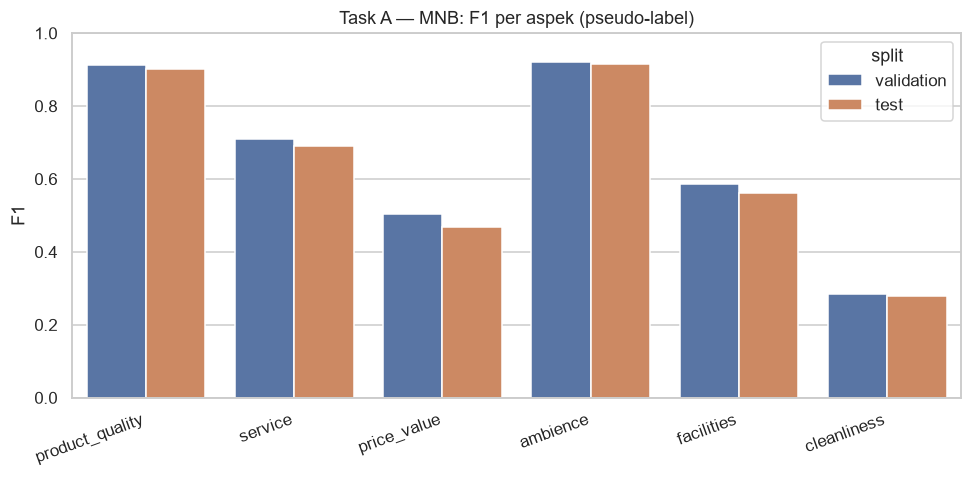

In [9]:
plot_df = a_metrics[~a_metrics["aspect"].str.endswith("avg")]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="aspect", y="f1", hue="split", ax=ax)
ax.set_title("Task A — MNB: F1 per aspek (pseudo-label)")
ax.set_xlabel("")
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task_a_f1_per_aspect.png", dpi=300)
plt.show()

### A.4 Simpan artefak handoff Task A

Vectorizer dan matriks TF-IDF disimpan agar SVM dan Random Forest memakai fitur yang persis sama (tidak fit ulang). `alignment_task_a.joblib` memuat `review_id` dan label tiap baris matriks, urutannya sama dengan baris `X_*`.

In [10]:
joblib.dump(tfidf_a, A_DIR / "tfidf_text_clean.joblib")
joblib.dump(A_X["train"], A_DIR / "X_train_text_clean.joblib")
joblib.dump(A_X["validation"], A_DIR / "X_validation_text_clean.joblib")
joblib.dump(A_X["test"], A_DIR / "X_test_text_clean.joblib")
joblib.dump(model_a, A_DIR / "model_mnb.joblib")

alignment_a = {
    "label_columns": ASPECT_LABEL_COLUMNS,
    **{
        split: {"review_id": A[split]["review_id"].tolist(), "y": A_Y[split]}
        for split in SPLITS
    },
}
joblib.dump(alignment_a, A_DIR / "alignment_task_a.joblib")
print("Artefak Task A tersimpan di", A_DIR.relative_to(PROJECT_ROOT).as_posix())

Artefak Task A tersimpan di data/processed/modeling/mnb/task_a


## Task B — MNB

Satu baris = satu pasangan review-aspek; target = `negative` / `neutral` / `positive`.

- **Baseline utama:** 6 classifier MNB terpisah, satu per `aspect_category` (TF-IDF `text_clean` yang di-fit pada train aspek tersebut).
- **Pembanding:** 1 classifier gabungan memakai `aspect_text_model` (teks diawali token aspek).

Distribusi kelas sangat timpang (positive jauh lebih banyak), jadi fokus ke **macro-F1** dan **recall negative**; accuracy hanya sebagai pelengkap.

### B.1 TF-IDF per aspek (fit hanya pada train aspek tersebut)

In [11]:
B = {
    aspect: {
        split: task_b[(task_b["aspect_category"] == aspect) & (task_b["split"] == split)]
        .reset_index(drop=True)
        for split in SPLITS
    }
    for aspect in ASPECTS
}

tfidf_b = {}
B_X = {split: {} for split in SPLITS}
B_y = {split: {} for split in SPLITS}

for aspect in ASPECTS:
    vectorizer = make_tfidf()
    B_X["train"][aspect] = vectorizer.fit_transform(B[aspect]["train"][TEXT_VARIANT])  # fit: hanya train
    B_X["validation"][aspect] = vectorizer.transform(B[aspect]["validation"][TEXT_VARIANT])
    B_X["test"][aspect] = vectorizer.transform(B[aspect]["test"][TEXT_VARIANT])
    for split in SPLITS:
        B_y[split][aspect] = B[aspect][split]["sentiment"].to_numpy()
    tfidf_b[aspect] = vectorizer

overview = pd.DataFrame({
    aspect: {
        "vocab": len(tfidf_b[aspect].vocabulary_),
        "n_train": len(B[aspect]["train"]),
        "n_val": len(B[aspect]["validation"]),
        "n_test": len(B[aspect]["test"]),
        "train_negative": int((B_y["train"][aspect] == "negative").sum()),
        "train_neutral": int((B_y["train"][aspect] == "neutral").sum()),
        "train_positive": int((B_y["train"][aspect] == "positive").sum()),
    }
    for aspect in ASPECTS
}).T
display(overview)

,vocab,n_train,n_val,n_test,train_negative,train_neutral,train_positive
product_quality,2675,950,351,350,20,241,689
service,1635,533,203,201,77,104,352
price_value,838,268,98,98,18,58,192
ambience,2861,1259,393,396,22,133,1104
facilities,925,189,64,64,27,83,79
cleanliness,373,114,34,33,12,10,92


### B.2 Memilih `alpha` untuk 6 model per-aspek (validation)

Satu nilai `alpha` dipakai bersama untuk keenam model per-aspek. Kriteria: rata-rata macro-F1 per aspek pada validation (tiap aspek berbobot sama). Validation per aspek kecil (mis. `cleanliness` hanya 34 baris), jadi satu `alpha` bersama lebih stabil daripada tuning terpisah. Test belum disentuh.

In [12]:
rows = []
for alpha in ALPHA_GRID:
    per_aspect_f1, pooled_true, pooled_pred = [], [], []
    for aspect in ASPECTS:
        candidate = MultinomialNB(alpha=alpha).fit(B_X["train"][aspect], B_y["train"][aspect])
        predicted = candidate.predict(B_X["validation"][aspect])
        per_aspect_f1.append(sentiment_metrics(B_y["validation"][aspect], predicted)["macro_f1"])
        pooled_true.append(B_y["validation"][aspect])
        pooled_pred.append(predicted)
    pooled = sentiment_metrics(np.concatenate(pooled_true), np.concatenate(pooled_pred))
    rows.append({
        "alpha": alpha,
        "val_mean_aspect_macro_f1": float(np.mean(per_aspect_f1)),
        "val_pooled_macro_f1": pooled["macro_f1"],
        "val_pooled_recall_negative": pooled["recall_negative"],
    })

b_tuning = pd.DataFrame(rows)
B_ALPHA = pick_alpha(b_tuning, "val_mean_aspect_macro_f1")
b_tuning["selected"] = b_tuning["alpha"] == B_ALPHA
display(b_tuning)
print("alpha terpilih (Task B per-aspek):", B_ALPHA)
b_tuning.to_csv(TABLES_DIR / "task_b_alpha_tuning_per_aspect.csv", index=False)

,alpha,val_mean_aspect_macro_f1,val_pooled_macro_f1,val_pooled_recall_negative,selected
0,0.001,0.450905,0.532477,0.226415,False
1,0.003,0.510821,0.557780,0.283019,False
2,0.010,0.514398,0.575043,0.339623,False
3,0.030,0.521618,0.585923,0.358491,True
4,0.100,0.478391,0.576496,0.339623,False
5,0.300,0.458917,0.545813,0.264151,False
6,0.500,0.438718,0.519476,0.207547,False
7,1.000,0.351692,0.420201,0.113208,False
8,2.000,0.317929,0.342316,0.000000,False


alpha terpilih (Task B per-aspek): 0.03


### B.3 Model final per-aspek dan evaluasi

**Test dievaluasi satu kali di sel ini** untuk keenam model per-aspek.

In [13]:
models_b = {
    aspect: MultinomialNB(alpha=B_ALPHA).fit(B_X["train"][aspect], B_y["train"][aspect])
    for aspect in ASPECTS
}
B_pred = {
    split: {aspect: models_b[aspect].predict(B_X[split][aspect]) for aspect in ASPECTS}
    for split in ("validation", "test")
}

metric_rows = []
for split in ("validation", "test"):
    for aspect in ASPECTS:
        metric_rows.append({"aspect": aspect, "split": split,
                            **sentiment_metrics(B_y[split][aspect], B_pred[split][aspect])})
    pooled = sentiment_metrics(
        np.concatenate([B_y[split][a] for a in ASPECTS]),
        np.concatenate([B_pred[split][a] for a in ASPECTS]),
    )
    metric_rows.append({"aspect": "ALL (pooled)", "split": split, **pooled})
    mean_row = {"aspect": "MEAN (per aspek)", "split": split}
    per_aspect_df = pd.DataFrame([r for r in metric_rows if r["split"] == split and r["aspect"] in ASPECTS])
    for column in ("accuracy", "macro_f1", "weighted_f1", "recall_negative"):
        mean_row[column] = per_aspect_df[column].mean()
    metric_rows.append(mean_row)

b_metrics_per_aspect = pd.DataFrame(metric_rows)
shown = ["aspect", "n_rows", "accuracy", "macro_f1", "weighted_f1", "recall_negative",
         "support_negative", "support_neutral", "support_positive"]
print("TEST — 6 model MNB per-aspek:")
display(b_metrics_per_aspect[b_metrics_per_aspect["split"] == "test"][shown].round(4))

b_metrics_per_aspect.to_csv(TABLES_DIR / "task_b_metrics_per_aspect.csv", index=False)

b_predictions = pd.concat(
    [
        pd.DataFrame({
            "annotation_id": B[aspect]["test"]["annotation_id"],
            "aspect_category": aspect,
            "sentiment_true": B_y["test"][aspect],
            "sentiment_pred": B_pred["test"][aspect],
            "split": "test",
        })
        for aspect in ASPECTS
    ],
    ignore_index=True,
)
b_predictions.to_csv(TABLES_DIR / "task_b_test_predictions.csv", index=False)

TEST — 6 model MNB per-aspek:


,aspect,n_rows,accuracy,macro_f1,weighted_f1,recall_negative,support_negative,support_neutral,support_positive
8,product_quality,350.0,0.7600,0.4228,0.7176,0.0000,6.0,98.0,246.0
9,service,201.0,0.7861,0.6690,0.7797,0.7200,25.0,38.0,138.0
10,price_value,98.0,0.8265,0.6619,0.8265,0.5000,4.0,19.0,75.0
11,ambience,396.0,0.8636,0.3469,0.8127,0.0000,6.0,49.0,341.0
12,facilities,64.0,0.5625,0.4094,0.5365,0.0000,8.0,29.0,27.0
13,cleanliness,33.0,0.8788,0.5710,0.8788,0.7500,4.0,2.0,27.0
14,ALL (pooled),1142.0,0.7986,0.6017,0.7762,0.4340,53.0,235.0,854.0
15,MEAN (per aspek),NaN,0.7796,0.5135,0.7586,0.3283,NaN,NaN,NaN


### B.4 Pembanding: satu classifier gabungan (`aspect_text_model`)

Satu TF-IDF dan satu MNB untuk semua pasangan review-aspek. `alpha` dipilih pada validation dengan macro-F1 gabungan, lalu test dievaluasi satu kali.

In [14]:
C = {split: task_b[task_b["split"] == split].reset_index(drop=True) for split in SPLITS}
C_y = {split: C[split]["sentiment"].to_numpy() for split in SPLITS}

tfidf_c = make_tfidf()
C_X = {"train": tfidf_c.fit_transform(C["train"]["aspect_text_model"])}   # fit: hanya train
C_X["validation"] = tfidf_c.transform(C["validation"]["aspect_text_model"])
C_X["test"] = tfidf_c.transform(C["test"]["aspect_text_model"])
print("Ukuran kosakata gabungan:", len(tfidf_c.vocabulary_), "| X_train:", C_X["train"].shape)

rows = []
for alpha in ALPHA_GRID:
    candidate = MultinomialNB(alpha=alpha).fit(C_X["train"], C_y["train"])
    m = sentiment_metrics(C_y["validation"], candidate.predict(C_X["validation"]))
    rows.append({"alpha": alpha, "val_macro_f1": m["macro_f1"], "val_recall_negative": m["recall_negative"]})
c_tuning = pd.DataFrame(rows)
C_ALPHA = pick_alpha(c_tuning, "val_macro_f1")
c_tuning["selected"] = c_tuning["alpha"] == C_ALPHA
display(c_tuning)
print("alpha terpilih (gabungan):", C_ALPHA)
c_tuning.to_csv(TABLES_DIR / "task_b_alpha_tuning_combined.csv", index=False)

# Model final + evaluasi (test satu kali).
model_c = MultinomialNB(alpha=C_ALPHA).fit(C_X["train"], C_y["train"])
C_pred = {split: model_c.predict(C_X[split]) for split in ("validation", "test")}

rows = []
for split in ("validation", "test"):
    rows.append({"aspect": "ALL (pooled)", "split": split,
                 **sentiment_metrics(C_y[split], C_pred[split])})
    per_aspect_rows = []
    for aspect in ASPECTS:
        mask = (C[split]["aspect_category"] == aspect).to_numpy()
        row = {"aspect": aspect, "split": split,
               **sentiment_metrics(C_y[split][mask], C_pred[split][mask])}
        per_aspect_rows.append(row)
        rows.append(row)
    mean_row = {"aspect": "MEAN (per aspek)", "split": split}
    for column in ("accuracy", "macro_f1", "weighted_f1", "recall_negative"):
        mean_row[column] = float(np.mean([r[column] for r in per_aspect_rows]))
    rows.append(mean_row)

b_metrics_combined = pd.DataFrame(rows)
print("TEST — model gabungan:")
display(b_metrics_combined[b_metrics_combined["split"] == "test"][shown].round(4))
b_metrics_combined.to_csv(TABLES_DIR / "task_b_metrics_combined.csv", index=False)

pd.DataFrame({
    "annotation_id": C["test"]["annotation_id"],
    "aspect_category": C["test"]["aspect_category"],
    "sentiment_true": C_y["test"],
    "sentiment_pred": C_pred["test"],
    "split": "test",
}).to_csv(TABLES_DIR / "task_b_test_predictions_combined.csv", index=False)

Ukuran kosakata gabungan: 10000 | X_train: (3313, 10000)


,alpha,val_macro_f1,val_recall_negative,selected
0,0.001,0.468522,0.188679,False
1,0.003,0.479031,0.226415,False
2,0.010,0.487560,0.283019,False
3,0.030,0.502855,0.320755,True
4,0.100,0.471372,0.150943,False
5,0.300,0.389801,0.000000,False
6,0.500,0.370118,0.000000,False
7,1.000,0.297071,0.000000,False
8,2.000,0.285285,0.000000,False


alpha terpilih (gabungan): 0.03
TEST — model gabungan:


,aspect,n_rows,accuracy,macro_f1,weighted_f1,recall_negative,support_negative,support_neutral,support_positive
8,ALL (pooled),1142.0,0.7671,0.5282,0.7459,0.3208,53.0,235.0,854.0
9,product_quality,350.0,0.7286,0.4304,0.6935,0.1667,6.0,98.0,246.0
10,service,201.0,0.7512,0.5922,0.7384,0.4400,25.0,38.0,138.0
11,price_value,98.0,0.7347,0.4775,0.7347,0.2500,4.0,19.0,75.0
12,ambience,396.0,0.8510,0.4906,0.8393,0.1667,6.0,49.0,341.0
13,facilities,64.0,0.5156,0.4105,0.4828,0.1250,8.0,29.0,27.0
14,cleanliness,33.0,0.8485,0.6420,0.8586,0.5000,4.0,2.0,27.0
15,MEAN (per aspek),NaN,0.7383,0.5072,0.7246,0.2747,NaN,NaN,NaN


### B.5 Confusion matrix (test)

Satu grid untuk 6 model per-aspek, dan satu untuk model gabungan (matriks gabungan di kiri, rincian per aspek di kanan). Disimpan 300 DPI.

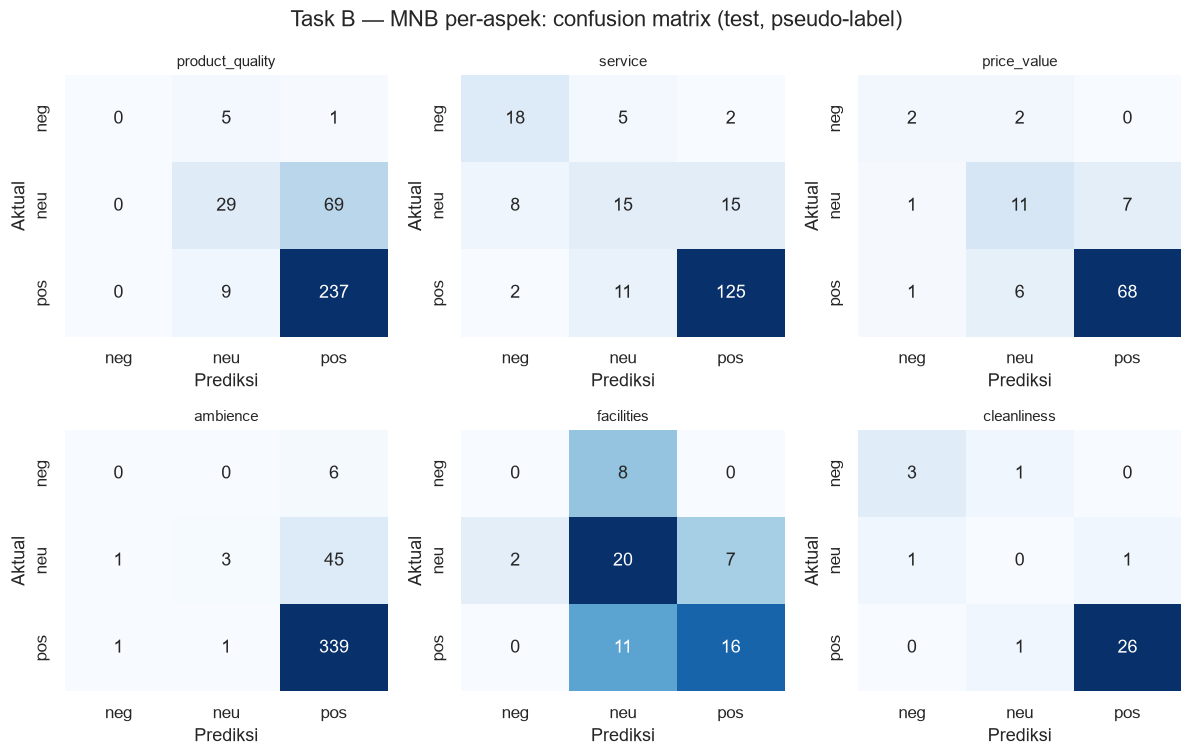

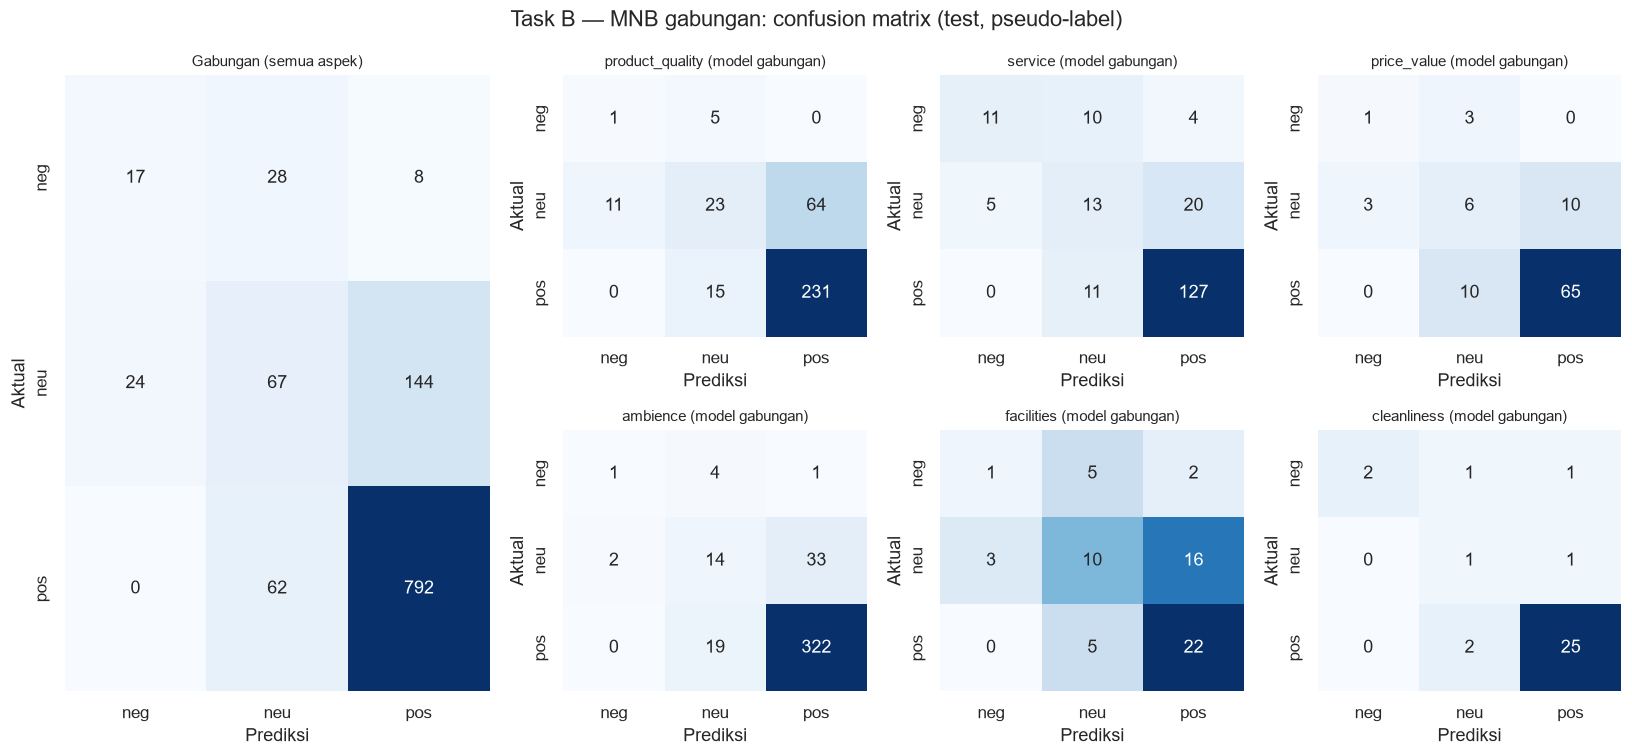

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, aspect in zip(axes.ravel(), ASPECTS):
    plot_confusion(ax, B_y["test"][aspect], B_pred["test"][aspect], aspect)
fig.suptitle("Task B — MNB per-aspek: confusion matrix (test, pseudo-label)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task_b_confusion_matrix.png", dpi=300)
plt.show()

fig = plt.figure(figsize=(15, 7))
grid = fig.add_gridspec(2, 4, width_ratios=[1.4, 1, 1, 1])
plot_confusion(fig.add_subplot(grid[:, 0]), C_y["test"], C_pred["test"], "Gabungan (semua aspek)")
for index, aspect in enumerate(ASPECTS):
    ax = fig.add_subplot(grid[index // 3, 1 + index % 3])
    mask = (C["test"]["aspect_category"] == aspect).to_numpy()
    plot_confusion(ax, C_y["test"][mask], C_pred["test"][mask], f"{aspect} (model gabungan)")
fig.suptitle("Task B — MNB gabungan: confusion matrix (test, pseudo-label)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task_b_confusion_matrix_combined.png", dpi=300)
plt.show()

### B.6 Ringkasan perbandingan per-aspek vs gabungan (test)

In [16]:
columns = ["accuracy", "macro_f1", "weighted_f1", "recall_negative"]
per_aspect_test = b_metrics_per_aspect[b_metrics_per_aspect["split"] == "test"].set_index("aspect")
combined_test = b_metrics_combined[b_metrics_combined["split"] == "test"].set_index("aspect")
comparison = pd.DataFrame({
    "per-aspek (6 MNB) — pooled": per_aspect_test.loc["ALL (pooled)", columns],
    "gabungan (1 MNB) — pooled": combined_test.loc["ALL (pooled)", columns],
    "per-aspek (6 MNB) — rata-rata aspek": per_aspect_test.loc["MEAN (per aspek)", columns],
    "gabungan (1 MNB) — rata-rata aspek": combined_test.loc["MEAN (per aspek)", columns],
}).T
display(comparison.round(4))

,accuracy,macro_f1,weighted_f1,recall_negative
per-aspek (6 MNB) — pooled,0.798599,0.601681,0.776207,0.433962
gabungan (1 MNB) — pooled,0.767075,0.528173,0.745935,0.320755
per-aspek (6 MNB) — rata-rata aspek,0.779587,0.513494,0.758644,0.328333
gabungan (1 MNB) — rata-rata aspek,0.738272,0.5072,0.72455,0.274722


### B.7 Simpan artefak handoff Task B

Struktur sesuai panduan (bagian 7.1). Dictionary per-aspek memakai kunci `aspect_category`. `alignment_task_b.joblib` memuat `annotation_id` dan label untuk tiap baris matriks.

In [17]:
joblib.dump(tfidf_b, B_DIR / "tfidf_text_clean_per_aspect.joblib")
for split in SPLITS:
    joblib.dump(B_X[split], B_DIR / f"X_{split}_text_clean_per_aspect.joblib")

joblib.dump(tfidf_c, B_DIR / "tfidf_aspect_text_model.joblib")
for split in SPLITS:
    joblib.dump(C_X[split], B_DIR / f"X_{split}_aspect_text_model.joblib")

for aspect in ASPECTS:
    joblib.dump(models_b[aspect], B_DIR / f"model_mnb_{aspect}.joblib")
joblib.dump(model_c, B_DIR / "model_mnb_combined.joblib")

alignment_b = {
    "per_aspect": {
        aspect: {
            split: {"annotation_id": B[aspect][split]["annotation_id"].tolist(), "y": B_y[split][aspect]}
            for split in SPLITS
        }
        for aspect in ASPECTS
    },
    "combined": {
        split: {
            "annotation_id": C[split]["annotation_id"].tolist(),
            "aspect_category": C[split]["aspect_category"].tolist(),
            "y": C_y[split],
        }
        for split in SPLITS
    },
}
joblib.dump(alignment_b, B_DIR / "alignment_task_b.joblib")
print("Artefak Task B tersimpan di", B_DIR.relative_to(PROJECT_ROOT).as_posix())

Artefak Task B tersimpan di data/processed/modeling/mnb/task_b


## 3. Manifest eksperimen

`data/processed/modeling/mnb/mnb_manifest.json` mencatat tanggal, penulis, versi library, varian teks, konfigurasi vectorizer dan model, `random_state`, hash input split, ringkasan metrik, dan daftar artefak. Kunci `task_a.macro_f1` dan `task_b.macro_f1` dipakai oleh perintah verifikasi cepat di panduan.

In [18]:
def relative(path: Path) -> str:
    return path.relative_to(PROJECT_ROOT).as_posix()


def test_row(frame: pd.DataFrame, name: str) -> pd.Series:
    return frame[(frame["split"] == "test") & (frame["aspect"] == name)].iloc[0]


a_test_macro = test_row(a_metrics, "macro avg")
a_test_micro = test_row(a_metrics, "micro avg")
per_pooled = test_row(b_metrics_per_aspect, "ALL (pooled)")
per_mean = test_row(b_metrics_per_aspect, "MEAN (per aspek)")
comb_pooled = test_row(b_metrics_combined, "ALL (pooled)")
comb_mean = test_row(b_metrics_combined, "MEAN (per aspek)")

vectorizer_config = {**TFIDF_PARAMS, "ngram_range": list(TFIDF_PARAMS["ngram_range"])}

manifest = {
    "date": datetime.now().astimezone().strftime("%Y-%m-%d"),
    "generated_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "author": AUTHOR,
    "algorithm": "MultinomialNB",
    "label_type": "pseudo-label (auto:lexical_preannotation_v1), bukan human gold",
    "environment": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
    "text_variant": {"task_a": TEXT_VARIANT, "task_b_per_aspect": TEXT_VARIANT,
                     "task_b_combined": "aspect_text_model"},
    "vectorizer_config": vectorizer_config,
    "model_config": {
        "task_a": f"OneVsRestClassifier(MultinomialNB(alpha={A_ALPHA}))",
        "task_b_per_aspect": f"6 x MultinomialNB(alpha={B_ALPHA})",
        "task_b_combined": f"MultinomialNB(alpha={C_ALPHA})",
        "alpha_grid": ALPHA_GRID,
        "alpha_selection": "validation only (macro-F1); test dievaluasi satu kali",
    },
    "random_state": {
        "mnb_models": None,
        "note": "MNB dan TF-IDF deterministik; tidak ada random_state.",
        "split_generation": split_manifest["configuration"]["random_state"],
    },
    "input_split_files": input_hashes,
    "task_a": {
        "alpha": A_ALPHA,
        "split": "test",
        "macro_f1": float(a_test_macro["f1"]),
        "micro_f1": float(a_test_micro["f1"]),
        "f1_per_aspect": {
            aspect: float(test_row(a_metrics, aspect)["f1"]) for aspect in ASPECTS
        },
    },
    "task_b": {
        "split": "test",
        "macro_f1": float(per_pooled["macro_f1"]),
        "per_aspect_models": {
            "alpha": B_ALPHA,
            "pooled_macro_f1": float(per_pooled["macro_f1"]),
            "pooled_weighted_f1": float(per_pooled["weighted_f1"]),
            "pooled_recall_negative": float(per_pooled["recall_negative"]),
            "mean_aspect_macro_f1": float(per_mean["macro_f1"]),
        },
        "combined_model": {
            "alpha": C_ALPHA,
            "pooled_macro_f1": float(comb_pooled["macro_f1"]),
            "pooled_weighted_f1": float(comb_pooled["weighted_f1"]),
            "pooled_recall_negative": float(comb_pooled["recall_negative"]),
            "mean_aspect_macro_f1": float(comb_mean["macro_f1"]),
        },
    },
}

MANIFEST_PATH = ARTIFACT_DIR / "mnb_manifest.json"
output_files = sorted(
    p for directory in (TABLES_DIR, FIGURES_DIR, ARTIFACT_DIR)
    for p in directory.rglob("*")
    if p.is_file() and p != MANIFEST_PATH
)
manifest["artifacts"] = [
    {"path": relative(p), "bytes": p.stat().st_size} for p in output_files
] + [{"path": relative(MANIFEST_PATH), "note": "file ini"}]

MANIFEST_PATH.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print("Manifest ditulis:", relative(MANIFEST_PATH), f"({len(manifest['artifacts'])} artefak tercatat)")

Manifest ditulis: data/processed/modeling/mnb/mnb_manifest.json (35 artefak tercatat)


## 4. Checklist sebelum push

Sel ini memverifikasi: artefak wajib ada, vectorizer + matriks yang tersimpan bisa dimuat ulang dan konsisten (cek ini yang akan dilakukan rekan SVM/RF), vectorizer hanya belajar dari baris train, dan manifest bisa dibaca.

In [19]:
expected_files = [
    TABLES_DIR / "task_a_metrics.csv",
    TABLES_DIR / "task_a_test_predictions.csv",
    TABLES_DIR / "task_b_metrics_per_aspect.csv",
    TABLES_DIR / "task_b_metrics_combined.csv",
    TABLES_DIR / "task_b_test_predictions.csv",
    FIGURES_DIR / "task_b_confusion_matrix.png",
    A_DIR / "tfidf_text_clean.joblib",
    A_DIR / "X_train_text_clean.joblib",
    A_DIR / "X_validation_text_clean.joblib",
    A_DIR / "X_test_text_clean.joblib",
    A_DIR / "model_mnb.joblib",
    B_DIR / "tfidf_text_clean_per_aspect.joblib",
    B_DIR / "tfidf_aspect_text_model.joblib",
    MANIFEST_PATH,
    *[B_DIR / f"X_{s}_text_clean_per_aspect.joblib" for s in SPLITS],
    *[B_DIR / f"X_{s}_aspect_text_model.joblib" for s in SPLITS],
    *[B_DIR / f"model_mnb_{a}.joblib" for a in ASPECTS],
]
missing = [relative(p) for p in expected_files if not p.is_file()]
assert not missing, f"Artefak hilang: {missing}"

# 1) Simulasi rekan SVM/RF: muat vectorizer + matriks, transform ulang, hasilnya harus sama
#    (toleransi 1e-12: fit_transform vs transform hanya berbeda pembulatan floating point).
def same_matrix(left, right, tol: float = 1e-12) -> bool:
    return (
        left.shape == right.shape
        and ((left != 0) != (right != 0)).nnz == 0
        and (abs(left - right).max() if left.nnz else 0.0) < tol
    )


loaded_vec = joblib.load(A_DIR / "tfidf_text_clean.joblib")
loaded_train = joblib.load(A_DIR / "X_train_text_clean.joblib")
loaded_test = joblib.load(A_DIR / "X_test_text_clean.joblib")
assert same_matrix(loaded_vec.transform(A["train"][TEXT_VARIANT]), loaded_train)
assert same_matrix(loaded_vec.transform(A["test"][TEXT_VARIANT]), loaded_test)

loaded_vec_b = joblib.load(B_DIR / "tfidf_text_clean_per_aspect.joblib")
loaded_test_b = joblib.load(B_DIR / "X_test_text_clean_per_aspect.joblib")
for aspect in ASPECTS:
    assert same_matrix(loaded_vec_b[aspect].transform(B[aspect]["test"][TEXT_VARIANT]), loaded_test_b[aspect])

loaded_vec_c = joblib.load(B_DIR / "tfidf_aspect_text_model.joblib")
loaded_test_c = joblib.load(B_DIR / "X_test_aspect_text_model.joblib")
assert same_matrix(loaded_vec_c.transform(C["test"]["aspect_text_model"]), loaded_test_c)

# 2) Ukuran matriks sesuai baris tiap split (vectorizer di-fit pada train saja, lihat sel A.1/B.1/B.4).
assert A_X["train"].shape[0] == len(A["train"]) and A_X["test"].shape[0] == len(A["test"])
assert all(B_X["train"][a].shape[0] == len(B[a]["train"]) for a in ASPECTS)
assert C_X["train"].shape[0] == len(C["train"])

# 3) Manifest bisa dibaca dan memuat kunci yang dipakai verifikasi cepat panduan.
m = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
print("Manifest:", m["date"], "| Task A macro-F1:", round(m["task_a"]["macro_f1"], 4),
      "| Task B macro-F1:", round(m["task_b"]["macro_f1"], 4))
print("Status hash input:", {k.split("/")[-1]: v["status"] for k, v in m["input_split_files"].items()})
print("Semua pemeriksaan lolos.")

Manifest: 2026-11-01 | Task A macro-F1: 0.6363 | Task B macro-F1: 0.6017
Status hash input: {'aspect_detection_with_split.csv': 'match', 'aspect_sentiment_with_split.csv': 'match'}
Semua pemeriksaan lolos.


## 5. Catatan evaluasi

- Seluruh metrik dihitung terhadap **pseudo-label** (`auto:lexical_preannotation_v1`). Angka di atas menunjukkan seberapa baik MNB meniru pseudo-labeler, bukan akurasi terhadap penilaian manusia.
- Test dievaluasi satu kali per keluarga model (Task A, 6 model per-aspek, model gabungan) setelah `alpha` dipilih pada validation.
- MNB tidak memiliki `class_weight`; kelas `negative` yang jarang dapat menghasilkan recall rendah. Ini bagian dari baseline dan menjadi pembanding bagi SVM/RF.
- Perbandingan MNB vs SVM vs Random Forest hanya sah jika ketiganya memakai split, vektor fitur, dan varian teks yang sama (lihat bagian 10 panduan handoff).

---
*Section SVM dan Random Forest ditambahkan di bawah ini oleh rekan tim setelah section MNB di-push.*

## Task A — SVM

Setup SVM untuk deteksi aspek memakai matriks TF-IDF MNB (`tfidf_a`) **tanpa fit ulang** agar fitur sama persis dengan MNB. Model: `OneVsRestClassifier(LinearSVC)` dengan `class_weight="balanced"` (kelas aspek sangat timpang, mis. `cleanliness`). `C` dipilih pada validation dengan macro-F1; test dievaluasi satu kali setelah tuning.


In [20]:
from sklearn.svm import LinearSVC

SVM_TABLES_DIR = PROJECT_ROOT / "reports" / "tables" / "modeling" / "svm"
SVM_FIGURES_DIR = PROJECT_ROOT / "reports" / "figures" / "modeling" / "svm"
SVM_ARTIFACT_DIR = PROJECT_ROOT / "data" / "processed" / "modeling" / "svm"
SVM_A_DIR = SVM_ARTIFACT_DIR / "task_a"
SVM_B_DIR = SVM_ARTIFACT_DIR / "task_b"
for directory in (SVM_TABLES_DIR, SVM_FIGURES_DIR, SVM_A_DIR, SVM_B_DIR):
    directory.mkdir(parents=True, exist_ok=True)

C_GRID_SVM = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
DEFAULT_C_SVM = 1.0
SVM_RANDOM_STATE = 42

# Feature matrices MNB sudah dimuat di sel sebelumnya (A_X, B_X, C_X).
print("C_grid:", C_GRID_SVM)


C_grid: [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]


### A.1 Memilih `C` pada validation

Grid `C` dievaluasi **hanya pada validation** memakai matriks TF-IDF yang sama dengan MNB. `random_state` dicatat di manifest untuk keterulangan.


In [21]:
rows = []
for c in C_GRID_SVM:
    candidate = OneVsRestClassifier(
        LinearSVC(C=c, class_weight="balanced", random_state=SVM_RANDOM_STATE, max_iter=5000),
    ).fit(A_X["train"], A_Y["train"])
    predicted = candidate.predict(A_X["validation"])
    rows.append({
        "C": c,
        "val_macro_f1": f1_score(A_Y["validation"], predicted, average="macro", zero_division=0),
        "val_micro_f1": f1_score(A_Y["validation"], predicted, average="micro", zero_division=0),
    })

a_svm_tuning = pd.DataFrame(rows)
# Helper pick_alpha() dari section MNB dipakai ulang (kolom di-rename sementara).
A_SVM_C = pick_alpha(a_svm_tuning.rename(columns={"C": "alpha"}), "val_macro_f1")
a_svm_tuning["selected"] = a_svm_tuning["C"] == A_SVM_C
display(a_svm_tuning)
print("C terpilih (Task A SVM):", A_SVM_C)
a_svm_tuning.to_csv(SVM_TABLES_DIR / "task_a_c_tuning.csv", index=False)


,C,val_macro_f1,val_micro_f1,selected
0,0.01,0.801942,0.840659,False
1,0.03,0.812040,0.856102,False
2,0.10,0.836948,0.882061,False
3,0.30,0.852778,0.908118,False
4,1.00,0.853323,0.911936,True
5,3.00,0.846400,0.909825,False
6,10.00,0.844322,0.909091,False


C terpilih (Task A SVM): 1.0


### A.2 Model final dan evaluasi (test satu kali)

Model final di-fit pada `train` dengan `C` terpilih. **Test dievaluasi satu kali di sel ini.**


In [22]:
model_a_svm = OneVsRestClassifier(
    LinearSVC(C=A_SVM_C, class_weight="balanced", random_state=SVM_RANDOM_STATE, max_iter=5000),
).fit(A_X["train"], A_Y["train"])

A_svm_pred = {split: model_a_svm.predict(A_X[split]) for split in ("validation", "test")}

a_svm_metrics = pd.concat(
    [task_a_metrics(A_Y[split], A_svm_pred[split], split) for split in ("validation", "test")],
    ignore_index=True,
)
display(a_svm_metrics[a_svm_metrics["split"] == "test"].round(4))
print("Validation (untuk perbandingan):")
display(a_svm_metrics[(a_svm_metrics["split"] == "validation") & a_svm_metrics["aspect"].str.endswith("avg")].round(4))

a_svm_metrics.to_csv(SVM_TABLES_DIR / "task_a_metrics.csv", index=False)

a_svm_predictions = pd.DataFrame({"review_id": A["test"]["review_id"]})
for i, aspect in enumerate(ASPECTS):
    a_svm_predictions[f"pred_{aspect}"] = A_svm_pred["test"][:, i]
a_svm_predictions["split"] = "test"
a_svm_predictions.to_csv(SVM_TABLES_DIR / "task_a_test_predictions.csv", index=False)


,aspect,precision,recall,f1,support,split
8,product_quality,0.9909,0.9008,0.9437,363,test
9,service,0.9815,0.7571,0.8548,210,test
10,price_value,0.9747,0.7404,0.8415,104,test
11,ambience,0.9920,0.9140,0.9514,407,test
12,facilities,0.9167,0.7432,0.8209,74,test
13,cleanliness,1.0000,0.7429,0.8525,35,test
14,macro avg,0.9760,0.7997,0.8775,1193,test
15,micro avg,0.9845,0.8516,0.9133,1193,test


Validation (untuk perbandingan):


,aspect,precision,recall,f1,support,split
6,macro avg,0.9648,0.7739,0.8533,1194,validation
7,micro avg,0.9779,0.8543,0.9119,1194,validation


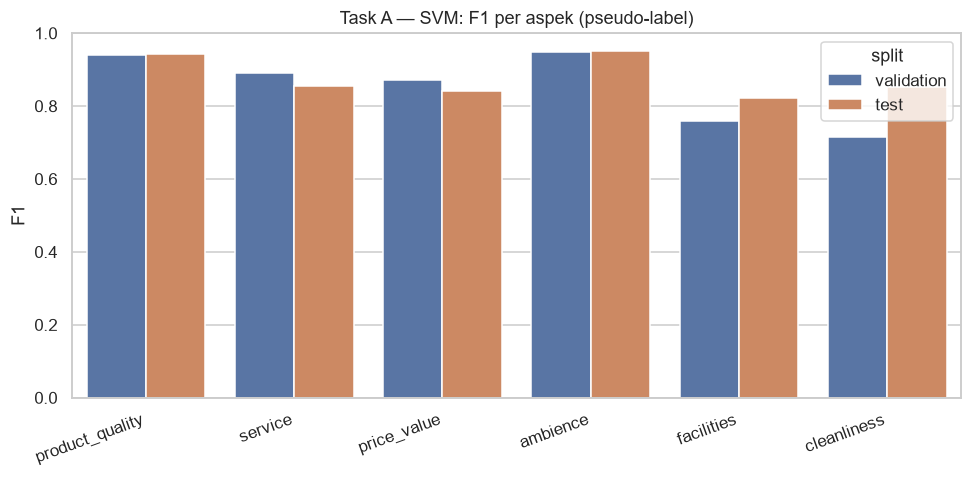

In [23]:
plot_df = a_svm_metrics[~a_svm_metrics["aspect"].str.endswith("avg")]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="aspect", y="f1", hue="split", ax=ax)
ax.set_title("Task A — SVM: F1 per aspek (pseudo-label)")
ax.set_xlabel("")
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(SVM_FIGURES_DIR / "task_a_f1_per_aspect.png", dpi=300)
plt.show()


### A.3 Simpan artefak handoff Task A SVM


In [24]:
joblib.dump(model_a_svm, SVM_A_DIR / "model_svm.joblib")
print("Artefak Task A SVM tersimpan di", SVM_A_DIR.relative_to(PROJECT_ROOT).as_posix())


Artefak Task A SVM tersimpan di data/processed/modeling/svm/task_a


## Task B — SVM

- **Baseline utama:** 6 classifier SVM terpisah, satu per `aspect_category` (matriks TF-IDF per-aspek MNB, `B_X`).
- **Pembanding:** 1 classifier SVM gabungan memakai matriks `C_X` (`aspect_text_model`).

Kelas sangat timpang, jadi dipakai `class_weight="balanced"` dan fokus evaluasi ke **macro-F1** dan **recall negative**.


### B.1 Memilih `C` untuk 6 model per-aspek (validation)

Satu nilai `C` dipakai bersama untuk keenam model per-aspek. Kriteria: rata-rata macro-F1 per aspek pada validation.


In [25]:
rows = []
for c in C_GRID_SVM:
    per_aspect_f1, pooled_true, pooled_pred = [], [], []
    for aspect in ASPECTS:
        candidate = LinearSVC(
            C=c, class_weight="balanced", random_state=SVM_RANDOM_STATE, max_iter=5000,
        ).fit(B_X["train"][aspect], B_y["train"][aspect])
        predicted = candidate.predict(B_X["validation"][aspect])
        per_aspect_f1.append(sentiment_metrics(B_y["validation"][aspect], predicted)["macro_f1"])
        pooled_true.append(B_y["validation"][aspect])
        pooled_pred.append(predicted)
    pooled = sentiment_metrics(np.concatenate(pooled_true), np.concatenate(pooled_pred))
    rows.append({
        "C": c,
        "val_mean_aspect_macro_f1": float(np.mean(per_aspect_f1)),
        "val_pooled_macro_f1": pooled["macro_f1"],
        "val_pooled_recall_negative": pooled["recall_negative"],
    })

b_svm_tuning = pd.DataFrame(rows)
B_SVM_C = pick_alpha(b_svm_tuning.rename(columns={"C": "alpha"}), "val_mean_aspect_macro_f1")
b_svm_tuning["selected"] = b_svm_tuning["C"] == B_SVM_C
display(b_svm_tuning)
print("C terpilih (Task B per-aspek SVM):", B_SVM_C)
b_svm_tuning.to_csv(SVM_TABLES_DIR / "task_b_c_tuning_per_aspect.csv", index=False)


,C,val_mean_aspect_macro_f1,val_pooled_macro_f1,val_pooled_recall_negative,selected
0,0.01,0.316096,0.343863,0.000000,False
1,0.03,0.373898,0.493886,0.245283,False
2,0.10,0.556855,0.596162,0.377358,False
3,0.30,0.592777,0.621573,0.433962,False
4,1.00,0.592699,0.632557,0.433962,False
5,3.00,0.612957,0.644166,0.452830,False
6,10.00,0.621867,0.641350,0.433962,True


C terpilih (Task B per-aspek SVM): 10.0


### B.2 Model final per-aspek dan evaluasi (test satu kali)


In [26]:
models_b_svm = {
    aspect: LinearSVC(
        C=B_SVM_C, class_weight="balanced", random_state=SVM_RANDOM_STATE, max_iter=5000,
    ).fit(B_X["train"][aspect], B_y["train"][aspect])
    for aspect in ASPECTS
}
B_svm_pred = {
    split: {aspect: models_b_svm[aspect].predict(B_X[split][aspect]) for aspect in ASPECTS}
    for split in ("validation", "test")
}

metric_rows = []
for split in ("validation", "test"):
    for aspect in ASPECTS:
        metric_rows.append({"aspect": aspect, "split": split,
                            **sentiment_metrics(B_y[split][aspect], B_svm_pred[split][aspect])})
    pooled = sentiment_metrics(
        np.concatenate([B_y[split][a] for a in ASPECTS]),
        np.concatenate([B_svm_pred[split][a] for a in ASPECTS]),
    )
    metric_rows.append({"aspect": "ALL (pooled)", "split": split, **pooled})
    mean_row = {"aspect": "MEAN (per aspek)", "split": split}
    per_aspect_df = pd.DataFrame([r for r in metric_rows if r["split"] == split and r["aspect"] in ASPECTS])
    for column in ("accuracy", "macro_f1", "weighted_f1", "recall_negative"):
        mean_row[column] = per_aspect_df[column].mean()
    metric_rows.append(mean_row)

b_svm_metrics_per_aspect = pd.DataFrame(metric_rows)
shown = ["aspect", "n_rows", "accuracy", "macro_f1", "weighted_f1", "recall_negative",
         "support_negative", "support_neutral", "support_positive"]
print("TEST — 6 model SVM per-aspek:")
display(b_svm_metrics_per_aspect[b_svm_metrics_per_aspect["split"] == "test"][shown].round(4))

b_svm_metrics_per_aspect.to_csv(SVM_TABLES_DIR / "task_b_metrics_per_aspect.csv", index=False)

b_svm_predictions = pd.concat(
    [
        pd.DataFrame({
            "annotation_id": B[aspect]["test"]["annotation_id"],
            "aspect_category": aspect,
            "sentiment_true": B_y["test"][aspect],
            "sentiment_pred": B_svm_pred["test"][aspect],
            "split": "test",
        })
        for aspect in ASPECTS
    ],
    ignore_index=True,
)
b_svm_predictions.to_csv(SVM_TABLES_DIR / "task_b_test_predictions.csv", index=False)


TEST — 6 model SVM per-aspek:


,aspect,n_rows,accuracy,macro_f1,weighted_f1,recall_negative,support_negative,support_neutral,support_positive
8,product_quality,350.0,0.7914,0.4798,0.7707,0.0000,6.0,98.0,246.0
9,service,201.0,0.8010,0.6747,0.7863,0.6800,25.0,38.0,138.0
10,price_value,98.0,0.8061,0.6375,0.8151,0.5000,4.0,19.0,75.0
11,ambience,396.0,0.8813,0.4527,0.8579,0.0000,6.0,49.0,341.0
12,facilities,64.0,0.6094,0.4960,0.5975,0.1250,8.0,29.0,27.0
13,cleanliness,33.0,0.8182,0.4206,0.8001,0.2500,4.0,2.0,27.0
14,ALL (pooled),1142.0,0.8161,0.6312,0.8033,0.3962,53.0,235.0,854.0
15,MEAN (per aspek),NaN,0.7846,0.5269,0.7713,0.2592,NaN,NaN,NaN


### B.3 Pembanding: satu classifier SVM gabungan (`aspect_text_model`)

`C` dipilih pada validation dengan macro-F1 gabungan, lalu test dievaluasi satu kali.


In [27]:
rows = []
for c in C_GRID_SVM:
    candidate = LinearSVC(
        C=c, class_weight="balanced", random_state=SVM_RANDOM_STATE, max_iter=5000,
    ).fit(C_X["train"], C_y["train"])
    m = sentiment_metrics(C_y["validation"], candidate.predict(C_X["validation"]))
    rows.append({"C": c, "val_macro_f1": m["macro_f1"], "val_recall_negative": m["recall_negative"]})

c_svm_tuning = pd.DataFrame(rows)
C_SVM_C = pick_alpha(c_svm_tuning.rename(columns={"C": "alpha"}), "val_macro_f1")
c_svm_tuning["selected"] = c_svm_tuning["C"] == C_SVM_C
display(c_svm_tuning)
print("C terpilih (gabungan SVM):", C_SVM_C)
c_svm_tuning.to_csv(SVM_TABLES_DIR / "task_b_c_tuning_combined.csv", index=False)

# Model final + evaluasi (test satu kali).
model_c_svm = LinearSVC(
    C=C_SVM_C, class_weight="balanced", random_state=SVM_RANDOM_STATE, max_iter=5000,
).fit(C_X["train"], C_y["train"])
C_svm_pred = {split: model_c_svm.predict(C_X[split]) for split in ("validation", "test")}

rows = []
for split in ("validation", "test"):
    rows.append({"aspect": "ALL (pooled)", "split": split,
                 **sentiment_metrics(C_y[split], C_svm_pred[split])})
    per_aspect_rows = []
    for aspect in ASPECTS:
        mask = (C[split]["aspect_category"] == aspect).to_numpy()
        row = {"aspect": aspect, "split": split,
               **sentiment_metrics(C_y[split][mask], C_svm_pred[split][mask])}
        per_aspect_rows.append(row)
        rows.append(row)
    mean_row = {"aspect": "MEAN (per aspek)", "split": split}
    for column in ("accuracy", "macro_f1", "weighted_f1", "recall_negative"):
        mean_row[column] = float(np.mean([r[column] for r in per_aspect_rows]))
    rows.append(mean_row)

b_svm_metrics_combined = pd.DataFrame(rows)
print("TEST — model gabungan SVM:")
display(b_svm_metrics_combined[b_svm_metrics_combined["split"] == "test"][shown].round(4))
b_svm_metrics_combined.to_csv(SVM_TABLES_DIR / "task_b_metrics_combined.csv", index=False)

pd.DataFrame({
    "annotation_id": C["test"]["annotation_id"],
    "aspect_category": C["test"]["aspect_category"],
    "sentiment_true": C_y["test"],
    "sentiment_pred": C_svm_pred["test"],
    "split": "test",
}).to_csv(SVM_TABLES_DIR / "task_b_test_predictions_combined.csv", index=False)


,C,val_macro_f1,val_recall_negative,selected
0,0.01,0.397630,0.301887,False
1,0.03,0.499200,0.660377,False
2,0.10,0.567361,0.622642,False
3,0.30,0.579226,0.603774,False
4,1.00,0.603708,0.547170,True
5,3.00,0.589892,0.452830,False
6,10.00,0.591519,0.528302,False


C terpilih (gabungan SVM): 1.0
TEST — model gabungan SVM:


,aspect,n_rows,accuracy,macro_f1,weighted_f1,recall_negative,support_negative,support_neutral,support_positive
8,ALL (pooled),1142.0,0.7837,0.5935,0.7739,0.5472,53.0,235.0,854.0
9,product_quality,350.0,0.7429,0.4619,0.7265,0.1667,6.0,98.0,246.0
10,service,201.0,0.7562,0.6148,0.7466,0.5600,25.0,38.0,138.0
11,price_value,98.0,0.7143,0.5325,0.7216,0.7500,4.0,19.0,75.0
12,ambience,396.0,0.8662,0.5734,0.8617,0.5000,6.0,49.0,341.0
13,facilities,64.0,0.6250,0.6078,0.6220,0.6250,8.0,29.0,27.0
14,cleanliness,33.0,0.9091,0.7159,0.9139,0.7500,4.0,2.0,27.0
15,MEAN (per aspek),NaN,0.7689,0.5844,0.7654,0.5586,NaN,NaN,NaN


### B.4 Confusion matrix (test)

Satu grid untuk 6 model per-aspek, dan satu untuk model gabungan. Disimpan 300 DPI.


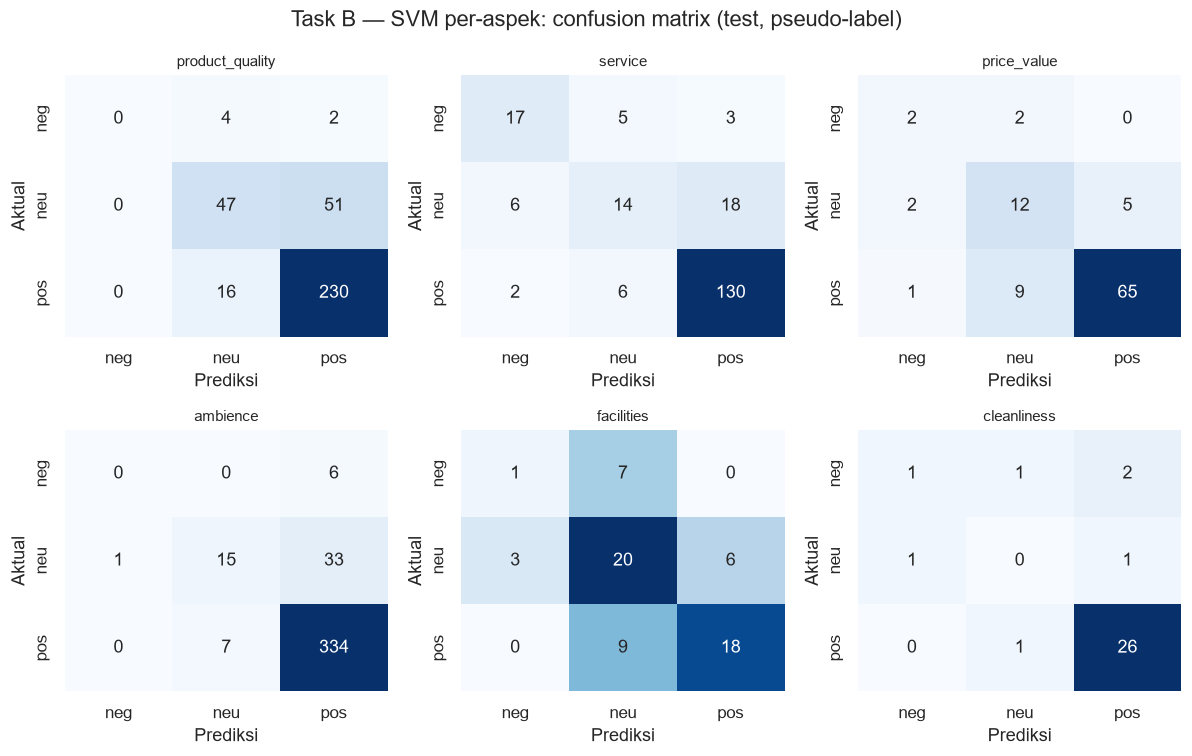

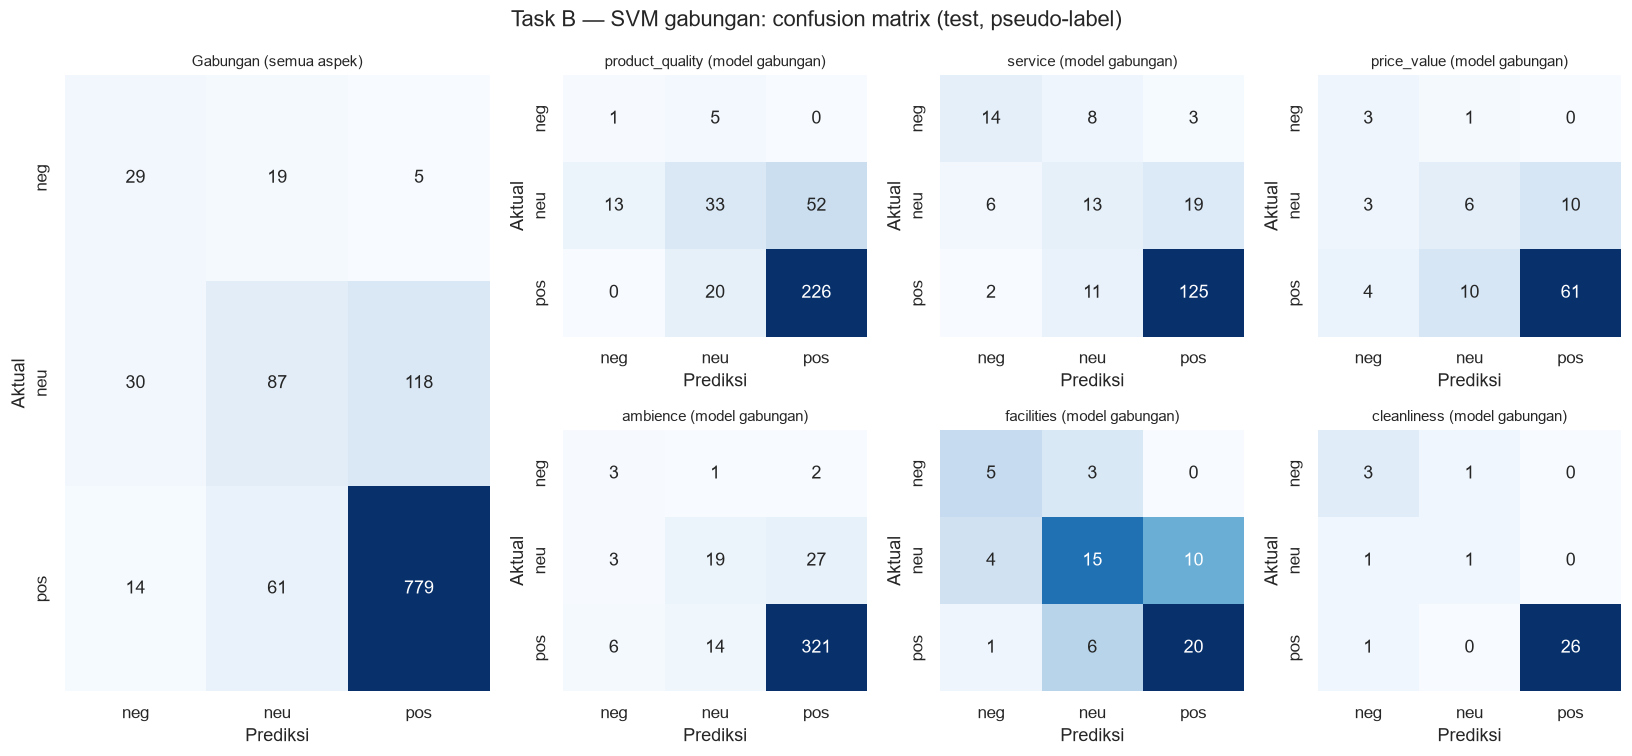

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, aspect in zip(axes.ravel(), ASPECTS):
    plot_confusion(ax, B_y["test"][aspect], B_svm_pred["test"][aspect], aspect)
fig.suptitle("Task B — SVM per-aspek: confusion matrix (test, pseudo-label)")
fig.tight_layout()
fig.savefig(SVM_FIGURES_DIR / "task_b_confusion_matrix.png", dpi=300)
plt.show()

fig = plt.figure(figsize=(15, 7))
grid = fig.add_gridspec(2, 4, width_ratios=[1.4, 1, 1, 1])
plot_confusion(fig.add_subplot(grid[:, 0]), C_y["test"], C_svm_pred["test"], "Gabungan (semua aspek)")
for index, aspect in enumerate(ASPECTS):
    ax = fig.add_subplot(grid[index // 3, 1 + index % 3])
    mask = (C["test"]["aspect_category"] == aspect).to_numpy()
    plot_confusion(ax, C_y["test"][mask], C_svm_pred["test"][mask], f"{aspect} (model gabungan)")
fig.suptitle("Task B — SVM gabungan: confusion matrix (test, pseudo-label)")
fig.tight_layout()
fig.savefig(SVM_FIGURES_DIR / "task_b_confusion_matrix_combined.png", dpi=300)
plt.show()


### B.5 Simpan artefak handoff Task B SVM


In [29]:
for aspect in ASPECTS:
    joblib.dump(models_b_svm[aspect], SVM_B_DIR / f"model_svm_{aspect}.joblib")
joblib.dump(model_c_svm, SVM_B_DIR / "model_svm_combined.joblib")
print("Artefak Task B SVM tersimpan di", SVM_B_DIR.relative_to(PROJECT_ROOT).as_posix())


Artefak Task B SVM tersimpan di data/processed/modeling/svm/task_b


## Manifest eksperimen SVM

`data/processed/modeling/svm/svm_manifest.json` mencatat tanggal, penulis, versi library, varian teks, konfigurasi vectorizer (diwarisi dari MNB, tidak di-fit ulang), `C` terpilih, `random_state`, hash input split, ringkasan metrik, dan daftar artefak.


In [30]:
a_test_macro = test_row(a_svm_metrics, "macro avg")
a_test_micro = test_row(a_svm_metrics, "micro avg")
per_pooled = test_row(b_svm_metrics_per_aspect, "ALL (pooled)")
per_mean = test_row(b_svm_metrics_per_aspect, "MEAN (per aspek)")
comb_pooled = test_row(b_svm_metrics_combined, "ALL (pooled)")
comb_mean = test_row(b_svm_metrics_combined, "MEAN (per aspek)")

svm_manifest = {
    "date": datetime.now().astimezone().strftime("%Y-%m-%d"),
    "generated_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "author": "Robby",  # ganti dengan nama Anda sebelum run
    "algorithm": "LinearSVC (SVM)",
    "label_type": "pseudo-label (auto:lexical_preannotation_v1), bukan human gold",
    "environment": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
    "text_variant": {"task_a": TEXT_VARIANT, "task_b_per_aspect": TEXT_VARIANT,
                     "task_b_combined": "aspect_text_model"},
    "vectorizer_config": {
        "note": "Diwarisi dari MNB (tfidf_a / tfidf_b / tfidf_c); tidak di-fit ulang agar fitur identik.",
        **vectorizer_config,
    },
    "model_config": {
        "task_a": f"OneVsRestClassifier(LinearSVC(C={A_SVM_C}, class_weight='balanced'))",
        "task_b_per_aspect": f"6 x LinearSVC(C={B_SVM_C}, class_weight='balanced')",
        "task_b_combined": f"LinearSVC(C={C_SVM_C}, class_weight='balanced')",
        "C_grid": C_GRID_SVM,
        "C_selection": "validation only (macro-F1); test dievaluasi satu kali",
    },
    "random_state": {
        "svm_models": SVM_RANDOM_STATE,
        "split_generation": split_manifest["configuration"]["random_state"],
    },
    "input_split_files": input_hashes,
    "task_a": {
        "C": A_SVM_C,
        "split": "test",
        "macro_f1": float(a_test_macro["f1"]),
        "micro_f1": float(a_test_micro["f1"]),
        "f1_per_aspect": {
            aspect: float(test_row(a_svm_metrics, aspect)["f1"]) for aspect in ASPECTS
        },
    },
    "task_b": {
        "split": "test",
        "macro_f1": float(per_pooled["macro_f1"]),
        "per_aspect_models": {
            "C": B_SVM_C,
            "pooled_macro_f1": float(per_pooled["macro_f1"]),
            "pooled_weighted_f1": float(per_pooled["weighted_f1"]),
            "pooled_recall_negative": float(per_pooled["recall_negative"]),
            "mean_aspect_macro_f1": float(per_mean["macro_f1"]),
        },
        "combined_model": {
            "C": C_SVM_C,
            "pooled_macro_f1": float(comb_pooled["macro_f1"]),
            "pooled_weighted_f1": float(comb_pooled["weighted_f1"]),
            "pooled_recall_negative": float(comb_pooled["recall_negative"]),
            "mean_aspect_macro_f1": float(comb_mean["macro_f1"]),
        },
    },
}

SVM_MANIFEST_PATH = SVM_ARTIFACT_DIR / "svm_manifest.json"
output_files = sorted(
    p for directory in (SVM_TABLES_DIR, SVM_FIGURES_DIR, SVM_ARTIFACT_DIR)
    for p in directory.rglob("*")
    if p.is_file() and p != SVM_MANIFEST_PATH
)
svm_manifest["artifacts"] = [
    {"path": relative(p), "bytes": p.stat().st_size} for p in output_files
] + [{"path": relative(SVM_MANIFEST_PATH), "note": "file ini"}]

SVM_MANIFEST_PATH.write_text(json.dumps(svm_manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print("Manifest SVM ditulis:", relative(SVM_MANIFEST_PATH), f"({len(svm_manifest['artifacts'])} artefak tercatat)")


Manifest SVM ditulis: data/processed/modeling/svm/svm_manifest.json (21 artefak tercatat)


## Checklist SVM sebelum push

Memverifikasi: artefak wajib ada, tidak ada artefak MNB yang tertimpa, model SVM yang tersimpan bisa dimuat ulang dan konsisten, dan manifest SVM bisa dibaca.


In [31]:
expected_svm_files = [
    SVM_TABLES_DIR / "task_a_c_tuning.csv",
    SVM_TABLES_DIR / "task_a_metrics.csv",
    SVM_TABLES_DIR / "task_a_test_predictions.csv",
    SVM_TABLES_DIR / "task_b_c_tuning_per_aspect.csv",
    SVM_TABLES_DIR / "task_b_c_tuning_combined.csv",
    SVM_TABLES_DIR / "task_b_metrics_per_aspect.csv",
    SVM_TABLES_DIR / "task_b_metrics_combined.csv",
    SVM_TABLES_DIR / "task_b_test_predictions.csv",
    SVM_TABLES_DIR / "task_b_test_predictions_combined.csv",
    SVM_FIGURES_DIR / "task_a_f1_per_aspect.png",
    SVM_FIGURES_DIR / "task_b_confusion_matrix.png",
    SVM_FIGURES_DIR / "task_b_confusion_matrix_combined.png",
    SVM_A_DIR / "model_svm.joblib",
    SVM_B_DIR / "model_svm_combined.joblib",
    SVM_MANIFEST_PATH,
    *[SVM_B_DIR / f"model_svm_{a}.joblib" for a in ASPECTS],
]
missing = [relative(p) for p in expected_svm_files if not p.is_file()]
assert not missing, f"Artefak SVM hilang: {missing}"

# Artefak MNB tidak boleh tertimpa: file kunci MNB harus tetap ada.
for mnb_file in (A_DIR / "model_mnb.joblib", B_DIR / "model_mnb_combined.joblib", MANIFEST_PATH):
    assert mnb_file.is_file(), f"Artefak MNB hilang: {relative(mnb_file)}"

# Model SVM yang tersimpan bisa dimuat ulang dan prediksinya konsisten.
reloaded_a = joblib.load(SVM_A_DIR / "model_svm.joblib")
assert (reloaded_a.predict(A_X["test"]) == A_svm_pred["test"]).all()
reloaded_c = joblib.load(SVM_B_DIR / "model_svm_combined.joblib")
assert (reloaded_c.predict(C_X["test"]) == C_svm_pred["test"]).all()

# Manifest SVM bisa dibaca dan memuat kunci verifikasi cepat.
m = json.loads(SVM_MANIFEST_PATH.read_text(encoding="utf-8"))
print("Manifest SVM:", m["date"], "| Task A macro-F1:", round(m["task_a"]["macro_f1"], 4),
      "| Task B macro-F1:", round(m["task_b"]["macro_f1"], 4))
print("Semua pemeriksaan SVM lolos.")


Manifest SVM: 2026-11-01 | Task A macro-F1: 0.8775 | Task B macro-F1: 0.6312
Semua pemeriksaan SVM lolos.


## Catatan evaluasi SVM

- Seluruh metrik dihitung terhadap **pseudo-label** (`auto:lexical_preannotation_v1`), bukan human gold.
- Test dievaluasi satu kali per keluarga model (Task A, 6 model per-aspek, model gabungan) setelah `C` dipilih pada validation.
- SVM memakai matriks TF-IDF yang di-fit MNB (tanpa fit ulang) agar perbandingan MNB vs SVM vs Random Forest sah.
- LinearSVC tidak menghasilkan probabilitas kalibrasi; Task A memakai keputusan biner per aspek, jadi `predict` sudah cukup. Jika kelak butuh skor kalibrasi, bisa diganti `SVC(probability=True)` — tapi itu mengubah baseline, diskusikan dulu.
- `class_weight="balanced"` dipakai agar recall `negative` naik; kenaikan itu harus dibayar kemungkinan turunnya presisi/precision — laporkan keduanya.


# Section Random Forest

Pembanding kedua setelah MNB dan SVM. Memakai matriks TF-IDF MNB (`tfidf_a`, `tfidf_b`, `tfidf_c`) **tanpa fit ulang** agar perbandingan tiga algoritma sah.

- Task A: `OneVsRestClassifier(RandomForestClassifier)` dengan `class_weight="balanced"`.
- Task B baseline utama: 6 Random Forest terpisah, satu per `aspect_category`.
- Task B pembanding: 1 Random Forest gabungan memakai `aspect_text_model`.

Grid `(n_estimators, max_depth, min_samples_leaf)` dipilih pada validation; test dievaluasi satu kali setelah tuning.


In [32]:
from sklearn.ensemble import RandomForestClassifier

RF_TABLES_DIR = PROJECT_ROOT / "reports" / "tables" / "modeling" / "rf"
RF_FIGURES_DIR = PROJECT_ROOT / "reports" / "figures" / "modeling" / "rf"
RF_ARTIFACT_DIR = PROJECT_ROOT / "data" / "processed" / "modeling" / "rf"
RF_A_DIR = RF_ARTIFACT_DIR / "task_a"
RF_B_DIR = RF_ARTIFACT_DIR / "task_b"
for directory in (RF_TABLES_DIR, RF_FIGURES_DIR, RF_A_DIR, RF_B_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RF_N_ESTIMATORS_GRID = [100, 300]
RF_MAX_DEPTH_GRID = [None, 20]
RF_MIN_SAMPLES_LEAF_GRID = [1, 5]
RF_RANDOM_STATE = 42

def pick_best_rf(tuning: pd.DataFrame, metric: str) -> pd.Series:
    """Baris grid dengan metrik validation tertinggi; seri dipecah ke model yang lebih sederhana."""
    ranked = tuning.sort_values(
        [metric, "max_depth", "n_estimators", "min_samples_leaf"],
        ascending=[False, True, True, False],
        na_position="last",
    )
    best = ranked.iloc[0]
    return {
        "n_estimators": int(best["n_estimators"]),
        "max_depth": None if pd.isna(best["max_depth"]) else int(best["max_depth"]),
        "min_samples_leaf": int(best["min_samples_leaf"]),
    }

def mark_selected(tuning: pd.DataFrame, n_est: int, max_depth, min_leaf: int) -> pd.Series:
    """Kolom boolean untuk menandai kombinasi terpilih; aman untuk max_depth=None."""
    depth_match = tuning["max_depth"].eq(max_depth) if max_depth is not None else tuning["max_depth"].isna()
    return (tuning["n_estimators"] == n_est) & depth_match & (tuning["min_samples_leaf"] == min_leaf)


### A.1 Tuning hyperparameter Task A pada validation

Grid dievaluasi **hanya pada validation** memakai matriks TF-IDF yang sama dengan MNB/SVM. `random_state` dan `n_jobs` dicatat di manifest untuk keterulangan.


In [33]:
rows = []
for n_est in RF_N_ESTIMATORS_GRID:
    for max_depth in RF_MAX_DEPTH_GRID:
        for min_leaf in RF_MIN_SAMPLES_LEAF_GRID:
            candidate = OneVsRestClassifier(
                RandomForestClassifier(
                    n_estimators=n_est, max_depth=max_depth,
                    min_samples_leaf=min_leaf, class_weight="balanced",
                    random_state=RF_RANDOM_STATE, n_jobs=-1,
                )
            ).fit(A_X["train"], A_Y["train"])
            predicted = candidate.predict(A_X["validation"])
            rows.append({
                "n_estimators": n_est,
                "max_depth": max_depth,
                "min_samples_leaf": min_leaf,
                "val_macro_f1": f1_score(A_Y["validation"], predicted, average="macro", zero_division=0),
                "val_micro_f1": f1_score(A_Y["validation"], predicted, average="micro", zero_division=0),
            })

a_rf_tuning = pd.DataFrame(rows)
a_rf_best = pick_best_rf(a_rf_tuning, "val_macro_f1")
A_RF_N_EST = int(a_rf_best["n_estimators"])
A_RF_MAX_DEPTH = a_rf_best["max_depth"]
A_RF_MIN_LEAF = int(a_rf_best["min_samples_leaf"])
a_rf_tuning["selected"] = mark_selected(a_rf_tuning, A_RF_N_EST, A_RF_MAX_DEPTH, A_RF_MIN_LEAF)
display(a_rf_tuning)
print("Hyperparameter terpilih (Task A RF): n_estimators =", A_RF_N_EST,
      "| max_depth =", A_RF_MAX_DEPTH, "| min_samples_leaf =", A_RF_MIN_LEAF)
a_rf_tuning.to_csv(RF_TABLES_DIR / "task_a_rf_tuning.csv", index=False)


,n_estimators,max_depth,min_samples_leaf,val_macro_f1,val_micro_f1,selected
0,100,NaN,1,0.833182,0.923348,False
1,100,NaN,5,0.815790,0.886023,False
2,100,20.0,1,0.850152,0.895042,False
3,100,20.0,5,0.806153,0.870886,False
4,300,NaN,1,0.850723,0.928352,False
5,300,NaN,5,0.803432,0.885572,False
6,300,20.0,1,0.854883,0.899688,True
7,300,20.0,5,0.801873,0.869012,False


Hyperparameter terpilih (Task A RF): n_estimators = 300 | max_depth = 20 | min_samples_leaf = 1


### A.2 Model final dan evaluasi (test satu kali)

Model final di-fit pada `train` dengan hyperparameter terpilih. **Test dievaluasi satu kali di sel ini.**


In [34]:
model_a_rf = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=A_RF_N_EST, max_depth=A_RF_MAX_DEPTH,
        min_samples_leaf=A_RF_MIN_LEAF, class_weight="balanced",
        random_state=RF_RANDOM_STATE, n_jobs=-1,
    )
).fit(A_X["train"], A_Y["train"])

A_rf_pred = {split: model_a_rf.predict(A_X[split]) for split in ("validation", "test")}

a_rf_metrics = pd.concat(
    [task_a_metrics(A_Y[split], A_rf_pred[split], split) for split in ("validation", "test")],
    ignore_index=True,
)
display(a_rf_metrics[a_rf_metrics["split"] == "test"].round(4))
print("Validation (untuk perbandingan):")
display(a_rf_metrics[(a_rf_metrics["split"] == "validation") & a_rf_metrics["aspect"].str.endswith("avg")].round(4))

a_rf_metrics.to_csv(RF_TABLES_DIR / "task_a_metrics.csv", index=False)

a_rf_predictions = pd.DataFrame({"review_id": A["test"]["review_id"]})
for i, aspect in enumerate(ASPECTS):
    a_rf_predictions[f"pred_{aspect}"] = A_rf_pred["test"][:, i]
a_rf_predictions["split"] = "test"
a_rf_predictions.to_csv(RF_TABLES_DIR / "task_a_test_predictions.csv", index=False)


,aspect,precision,recall,f1,support,split
8,product_quality,0.9735,0.9118,0.9417,363,test
9,service,0.9215,0.8381,0.8778,210,test
10,price_value,0.9875,0.7596,0.8587,104,test
11,ambience,0.9970,0.8280,0.9047,407,test
12,facilities,0.7250,0.7838,0.7532,74,test
13,cleanliness,1.0000,0.7143,0.8333,35,test
14,macro avg,0.9341,0.8059,0.8616,1193,test
15,micro avg,0.9545,0.8433,0.8954,1193,test


Validation (untuk perbandingan):


,aspect,precision,recall,f1,support,split
6,macro avg,0.9409,0.7951,0.8549,1194,validation
7,micro avg,0.9619,0.8451,0.8997,1194,validation


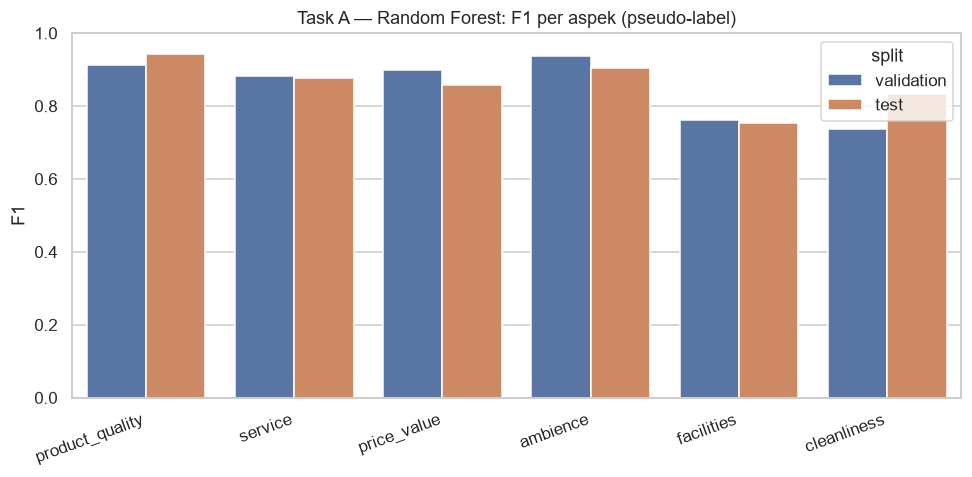

In [35]:
plot_df = a_rf_metrics[~a_rf_metrics["aspect"].str.endswith("avg")]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="aspect", y="f1", hue="split", ax=ax)
ax.set_title("Task A — Random Forest: F1 per aspek (pseudo-label)")
ax.set_xlabel("")
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(RF_FIGURES_DIR / "task_a_f1_per_aspect.png", dpi=300)
plt.show()


### A.3 Simpan artefak handoff Task A RF


In [36]:
joblib.dump(model_a_rf, RF_A_DIR / "model_rf.joblib")
print("Artefak Task A RF tersimpan di", RF_A_DIR.relative_to(PROJECT_ROOT).as_posix())


Artefak Task A RF tersimpan di data/processed/modeling/rf/task_a


## Task B — Random Forest

- **Baseline utama:** 6 Random Forest terpisah, satu per `aspect_category` (matriks TF-IDF per-aspek MNB, `B_X`).
- **Pembanding:** 1 Random Forest gabungan memakai matriks `C_X` (`aspect_text_model`).

Kelas sangat timpang, jadi dipakai `class_weight="balanced"` dan fokus evaluasi ke **macro-F1** dan **recall negative**.


### B.1 Tuning hyperparameter untuk 6 model per-aspek (validation)

Satu kombinasi hyperparameter dipakai bersama untuk keenam model per-aspek. Kriteria: rata-rata macro-F1 per aspek pada validation.


In [37]:
rows = []
for n_est in RF_N_ESTIMATORS_GRID:
    for max_depth in RF_MAX_DEPTH_GRID:
        for min_leaf in RF_MIN_SAMPLES_LEAF_GRID:
            per_aspect_f1, pooled_true, pooled_pred = [], [], []
            for aspect in ASPECTS:
                candidate = RandomForestClassifier(
                    n_estimators=n_est, max_depth=max_depth,
                    min_samples_leaf=min_leaf, class_weight="balanced",
                    random_state=RF_RANDOM_STATE, n_jobs=-1,
                ).fit(B_X["train"][aspect], B_y["train"][aspect])
                predicted = candidate.predict(B_X["validation"][aspect])
                per_aspect_f1.append(sentiment_metrics(B_y["validation"][aspect], predicted)["macro_f1"])
                pooled_true.append(B_y["validation"][aspect])
                pooled_pred.append(predicted)
            pooled = sentiment_metrics(np.concatenate(pooled_true), np.concatenate(pooled_pred))
            rows.append({
                "n_estimators": n_est,
                "max_depth": max_depth,
                "min_samples_leaf": min_leaf,
                "val_mean_aspect_macro_f1": float(np.mean(per_aspect_f1)),
                "val_pooled_macro_f1": pooled["macro_f1"],
                "val_pooled_recall_negative": pooled["recall_negative"],
            })

b_rf_tuning = pd.DataFrame(rows)
b_rf_best = pick_best_rf(b_rf_tuning, "val_mean_aspect_macro_f1")
B_RF_N_EST = int(b_rf_best["n_estimators"])
B_RF_MAX_DEPTH = b_rf_best["max_depth"]
B_RF_MIN_LEAF = int(b_rf_best["min_samples_leaf"])
b_rf_tuning["selected"] = mark_selected(b_rf_tuning, B_RF_N_EST, B_RF_MAX_DEPTH, B_RF_MIN_LEAF)
display(b_rf_tuning)
print("Hyperparameter terpilih (Task B per-aspek RF): n_estimators =", B_RF_N_EST,
      "| max_depth =", B_RF_MAX_DEPTH, "| min_samples_leaf =", B_RF_MIN_LEAF)
b_rf_tuning.to_csv(RF_TABLES_DIR / "task_b_rf_tuning_per_aspect.csv", index=False)


,n_estimators,max_depth,min_samples_leaf,val_mean_aspect_macro_f1,val_pooled_macro_f1,val_pooled_recall_negative,selected
0,100,NaN,1,0.607430,0.675245,0.490566,False
1,100,NaN,5,0.564629,0.599624,0.735849,False
2,100,20.0,1,0.601546,0.663302,0.490566,False
3,100,20.0,5,0.564564,0.598275,0.716981,False
4,300,NaN,1,0.609669,0.668611,0.452830,True
5,300,NaN,5,0.561563,0.600214,0.716981,False
6,300,20.0,1,0.607943,0.664979,0.471698,False
7,300,20.0,5,0.560747,0.598066,0.716981,False


Hyperparameter terpilih (Task B per-aspek RF): n_estimators = 300 | max_depth = None | min_samples_leaf = 1


### B.2 Model final per-aspek dan evaluasi (test satu kali)


In [38]:
models_b_rf = {
    aspect: RandomForestClassifier(
        n_estimators=B_RF_N_EST, max_depth=B_RF_MAX_DEPTH,
        min_samples_leaf=B_RF_MIN_LEAF, class_weight="balanced",
        random_state=RF_RANDOM_STATE, n_jobs=-1,
    ).fit(B_X["train"][aspect], B_y["train"][aspect])
    for aspect in ASPECTS
}
B_rf_pred = {
    split: {aspect: models_b_rf[aspect].predict(B_X[split][aspect]) for aspect in ASPECTS}
    for split in ("validation", "test")
}

metric_rows = []
for split in ("validation", "test"):
    for aspect in ASPECTS:
        metric_rows.append({"aspect": aspect, "split": split,
                            **sentiment_metrics(B_y[split][aspect], B_rf_pred[split][aspect])})
    pooled = sentiment_metrics(
        np.concatenate([B_y[split][a] for a in ASPECTS]),
        np.concatenate([B_rf_pred[split][a] for a in ASPECTS]),
    )
    metric_rows.append({"aspect": "ALL (pooled)", "split": split, **pooled})
    mean_row = {"aspect": "MEAN (per aspek)", "split": split}
    per_aspect_df = pd.DataFrame([r for r in metric_rows if r["split"] == split and r["aspect"] in ASPECTS])
    for column in ("accuracy", "macro_f1", "weighted_f1", "recall_negative"):
        mean_row[column] = per_aspect_df[column].mean()
    metric_rows.append(mean_row)

b_rf_metrics_per_aspect = pd.DataFrame(metric_rows)
shown = ["aspect", "n_rows", "accuracy", "macro_f1", "weighted_f1", "recall_negative",
         "support_negative", "support_neutral", "support_positive"]
print("TEST — 6 model RF per-aspek:")
display(b_rf_metrics_per_aspect[b_rf_metrics_per_aspect["split"] == "test"][shown].round(4))

b_rf_metrics_per_aspect.to_csv(RF_TABLES_DIR / "task_b_metrics_per_aspect.csv", index=False)

b_rf_predictions = pd.concat(
    [
        pd.DataFrame({
            "annotation_id": B[aspect]["test"]["annotation_id"],
            "aspect_category": aspect,
            "sentiment_true": B_y["test"][aspect],
            "sentiment_pred": B_rf_pred["test"][aspect],
            "split": "test",
        })
        for aspect in ASPECTS
    ],
    ignore_index=True,
)
b_rf_predictions.to_csv(RF_TABLES_DIR / "task_b_test_predictions.csv", index=False)


TEST — 6 model RF per-aspek:


,aspect,n_rows,accuracy,macro_f1,weighted_f1,recall_negative,support_negative,support_neutral,support_positive
8,product_quality,350.0,0.8629,0.5569,0.8550,0.0000,6.0,98.0,246.0
9,service,201.0,0.8010,0.7196,0.7970,0.8400,25.0,38.0,138.0
10,price_value,98.0,0.7755,0.6449,0.7919,0.5000,4.0,19.0,75.0
11,ambience,396.0,0.8763,0.4287,0.8472,0.0000,6.0,49.0,341.0
12,facilities,64.0,0.6562,0.5278,0.6393,0.1250,8.0,29.0,27.0
13,cleanliness,33.0,0.9091,0.7852,0.9153,1.0000,4.0,2.0,27.0
14,ALL (pooled),1142.0,0.8389,0.7013,0.8347,0.5283,53.0,235.0,854.0
15,MEAN (per aspek),NaN,0.8135,0.6105,0.8076,0.4108,NaN,NaN,NaN


### B.3 Pembanding: satu Random Forest gabungan (`aspect_text_model`)

Hyperparameter dipilih pada validation dengan macro-F1 gabungan, lalu test dievaluasi satu kali.


In [39]:
rows = []
for n_est in RF_N_ESTIMATORS_GRID:
    for max_depth in RF_MAX_DEPTH_GRID:
        for min_leaf in RF_MIN_SAMPLES_LEAF_GRID:
            candidate = RandomForestClassifier(
                n_estimators=n_est, max_depth=max_depth,
                min_samples_leaf=min_leaf, class_weight="balanced",
                random_state=RF_RANDOM_STATE, n_jobs=-1,
            ).fit(C_X["train"], C_y["train"])
            m = sentiment_metrics(C_y["validation"], candidate.predict(C_X["validation"]))
            rows.append({
                "n_estimators": n_est,
                "max_depth": max_depth,
                "min_samples_leaf": min_leaf,
                "val_macro_f1": m["macro_f1"],
                "val_recall_negative": m["recall_negative"],
            })

c_rf_tuning = pd.DataFrame(rows)
c_rf_best = pick_best_rf(c_rf_tuning, "val_macro_f1")
C_RF_N_EST = int(c_rf_best["n_estimators"])
C_RF_MAX_DEPTH = c_rf_best["max_depth"]
C_RF_MIN_LEAF = int(c_rf_best["min_samples_leaf"])
c_rf_tuning["selected"] = mark_selected(c_rf_tuning, C_RF_N_EST, C_RF_MAX_DEPTH, C_RF_MIN_LEAF)
display(c_rf_tuning)
print("Hyperparameter terpilih (gabungan RF): n_estimators =", C_RF_N_EST,
      "| max_depth =", C_RF_MAX_DEPTH, "| min_samples_leaf =", C_RF_MIN_LEAF)
c_rf_tuning.to_csv(RF_TABLES_DIR / "task_b_rf_tuning_combined.csv", index=False)

# Model final + evaluasi (test satu kali).
model_c_rf = RandomForestClassifier(
    n_estimators=C_RF_N_EST, max_depth=C_RF_MAX_DEPTH,
    min_samples_leaf=C_RF_MIN_LEAF, class_weight="balanced",
    random_state=RF_RANDOM_STATE, n_jobs=-1,
).fit(C_X["train"], C_y["train"])
C_rf_pred = {split: model_c_rf.predict(C_X[split]) for split in ("validation", "test")}

rows = []
for split in ("validation", "test"):
    rows.append({"aspect": "ALL (pooled)", "split": split,
                 **sentiment_metrics(C_y[split], C_rf_pred[split])})
    per_aspect_rows = []
    for aspect in ASPECTS:
        mask = (C[split]["aspect_category"] == aspect).to_numpy()
        row = {"aspect": aspect, "split": split,
               **sentiment_metrics(C_y[split][mask], C_rf_pred[split][mask])}
        per_aspect_rows.append(row)
        rows.append(row)
    mean_row = {"aspect": "MEAN (per aspek)", "split": split}
    for column in ("accuracy", "macro_f1", "weighted_f1", "recall_negative"):
        mean_row[column] = float(np.mean([r[column] for r in per_aspect_rows]))
    rows.append(mean_row)

b_rf_metrics_combined = pd.DataFrame(rows)
print("TEST — model gabungan RF:")
display(b_rf_metrics_combined[b_rf_metrics_combined["split"] == "test"][shown].round(4))
b_rf_metrics_combined.to_csv(RF_TABLES_DIR / "task_b_metrics_combined.csv", index=False)

pd.DataFrame({
    "annotation_id": C["test"]["annotation_id"],
    "aspect_category": C["test"]["aspect_category"],
    "sentiment_true": C_y["test"],
    "sentiment_pred": C_rf_pred["test"],
    "split": "test",
}).to_csv(RF_TABLES_DIR / "task_b_test_predictions_combined.csv", index=False)


,n_estimators,max_depth,min_samples_leaf,val_macro_f1,val_recall_negative,selected
0,100,NaN,1,0.573203,0.490566,False
1,100,NaN,5,0.525863,0.905660,False
2,100,20.0,1,0.536304,0.773585,False
3,100,20.0,5,0.514568,0.924528,False
4,300,NaN,1,0.598509,0.528302,True
5,300,NaN,5,0.524334,0.905660,False
6,300,20.0,1,0.553187,0.735849,False
7,300,20.0,5,0.521152,0.905660,False


Hyperparameter terpilih (gabungan RF): n_estimators = 300 | max_depth = None | min_samples_leaf = 1
TEST — model gabungan RF:


,aspect,n_rows,accuracy,macro_f1,weighted_f1,recall_negative,support_negative,support_neutral,support_positive
8,ALL (pooled),1142.0,0.8082,0.6447,0.8042,0.4906,53.0,235.0,854.0
9,product_quality,350.0,0.8171,0.5163,0.8112,0.0000,6.0,98.0,246.0
10,service,201.0,0.7910,0.7127,0.7926,0.6800,25.0,38.0,138.0
11,price_value,98.0,0.7347,0.5297,0.7422,0.5000,4.0,19.0,75.0
12,ambience,396.0,0.8611,0.5594,0.8513,0.5000,6.0,49.0,341.0
13,facilities,64.0,0.5781,0.4687,0.5612,0.1250,8.0,29.0,27.0
14,cleanliness,33.0,0.8485,0.5645,0.8628,0.7500,4.0,2.0,27.0
15,MEAN (per aspek),NaN,0.7718,0.5585,0.7702,0.4258,NaN,NaN,NaN


### B.4 Confusion matrix (test)

Satu grid untuk 6 model per-aspek, dan satu untuk model gabungan. Disimpan 300 DPI.


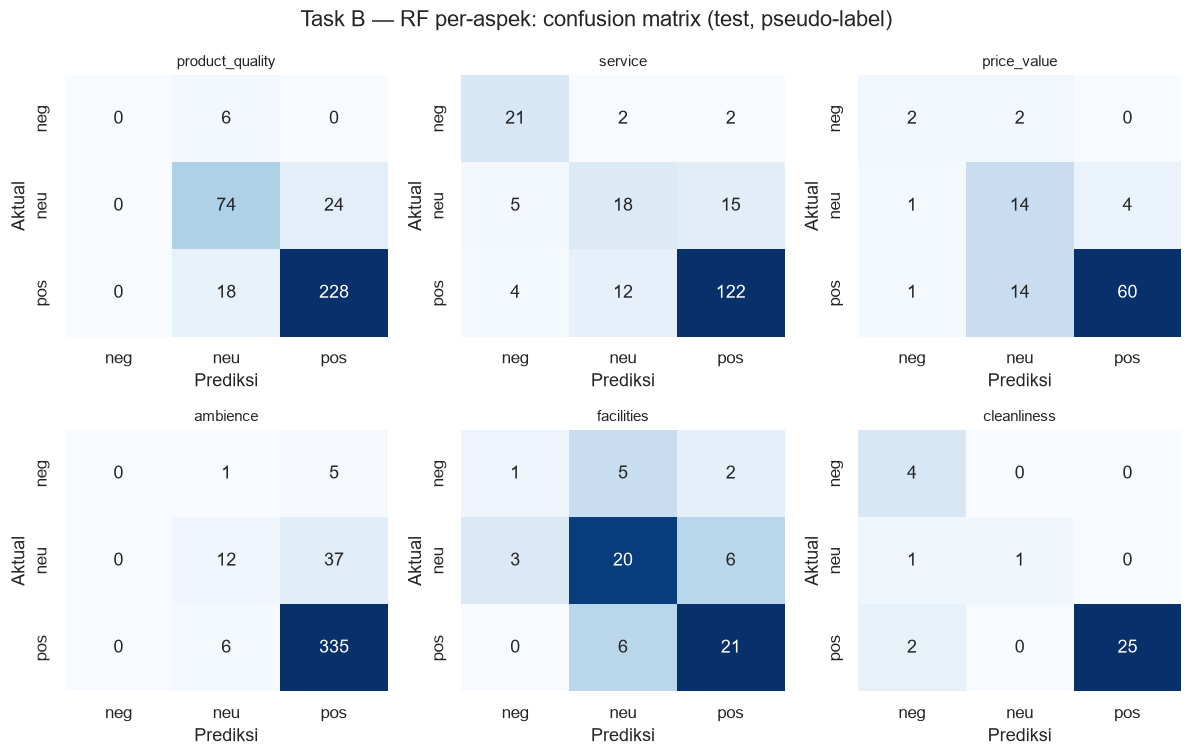

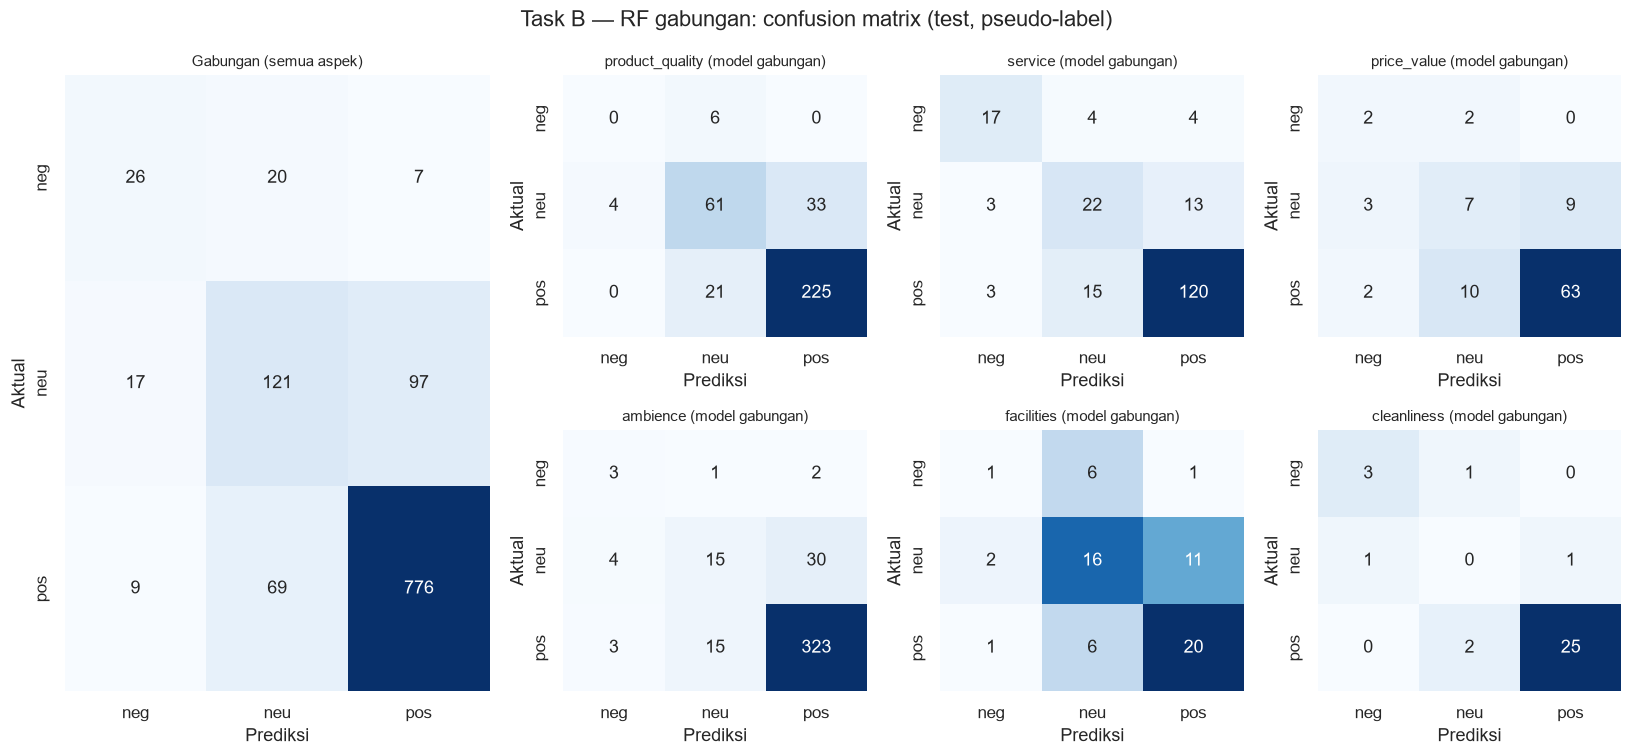

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, aspect in zip(axes.ravel(), ASPECTS):
    plot_confusion(ax, B_y["test"][aspect], B_rf_pred["test"][aspect], aspect)
fig.suptitle("Task B — RF per-aspek: confusion matrix (test, pseudo-label)")
fig.tight_layout()
fig.savefig(RF_FIGURES_DIR / "task_b_confusion_matrix.png", dpi=300)
plt.show()

fig = plt.figure(figsize=(15, 7))
grid = fig.add_gridspec(2, 4, width_ratios=[1.4, 1, 1, 1])
plot_confusion(fig.add_subplot(grid[:, 0]), C_y["test"], C_rf_pred["test"], "Gabungan (semua aspek)")
for index, aspect in enumerate(ASPECTS):
    ax = fig.add_subplot(grid[index // 3, 1 + index % 3])
    mask = (C["test"]["aspect_category"] == aspect).to_numpy()
    plot_confusion(ax, C_y["test"][mask], C_rf_pred["test"][mask], f"{aspect} (model gabungan)")
fig.suptitle("Task B — RF gabungan: confusion matrix (test, pseudo-label)")
fig.tight_layout()
fig.savefig(RF_FIGURES_DIR / "task_b_confusion_matrix_combined.png", dpi=300)
plt.show()


### B.5 Simpan artefak handoff Task B RF


In [41]:
for aspect in ASPECTS:
    joblib.dump(models_b_rf[aspect], RF_B_DIR / f"model_rf_{aspect}.joblib")
joblib.dump(model_c_rf, RF_B_DIR / "model_rf_combined.joblib")
print("Artefak Task B RF tersimpan di", RF_B_DIR.relative_to(PROJECT_ROOT).as_posix())


Artefak Task B RF tersimpan di data/processed/modeling/rf/task_b


## Manifest eksperimen Random Forest

`data/processed/modeling/rf/rf_manifest.json` mencatat tanggal, penulis, versi library, varian teks, konfigurasi vectorizer (diwarisi dari MNB, tidak di-fit ulang), hyperparameter terpilih, `random_state`, hash input split, ringkasan metrik, dan daftar artefak.


In [42]:
a_test_macro = test_row(a_rf_metrics, "macro avg")
a_test_micro = test_row(a_rf_metrics, "micro avg")
per_pooled = test_row(b_rf_metrics_per_aspect, "ALL (pooled)")
per_mean = test_row(b_rf_metrics_per_aspect, "MEAN (per aspek)")
comb_pooled = test_row(b_rf_metrics_combined, "ALL (pooled)")
comb_mean = test_row(b_rf_metrics_combined, "MEAN (per aspek)")

rf_manifest = {
    "date": datetime.now().astimezone().strftime("%Y-%m-%d"),
    "generated_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "author": "Robby",  
    "algorithm": "RandomForestClassifier",
    "label_type": "pseudo-label (auto:lexical_preannotation_v1), bukan human gold",
    "environment": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
    "text_variant": {"task_a": TEXT_VARIANT, "task_b_per_aspect": TEXT_VARIANT,
                     "task_b_combined": "aspect_text_model"},
    "vectorizer_config": {
        "note": "Diwarisi dari MNB (tfidf_a / tfidf_b / tfidf_c); tidak di-fit ulang agar fitur identik.",
        **vectorizer_config,
    },
    "model_config": {
        "task_a": {
            "estimator": "OneVsRestClassifier(RandomForestClassifier)",
            "n_estimators": A_RF_N_EST, "max_depth": A_RF_MAX_DEPTH,
            "min_samples_leaf": A_RF_MIN_LEAF, "class_weight": "balanced",
        },
        "task_b_per_aspect": {
            "estimator": "6 x RandomForestClassifier",
            "n_estimators": B_RF_N_EST, "max_depth": B_RF_MAX_DEPTH,
            "min_samples_leaf": B_RF_MIN_LEAF, "class_weight": "balanced",
        },
        "task_b_combined": {
            "estimator": "RandomForestClassifier",
            "n_estimators": C_RF_N_EST, "max_depth": C_RF_MAX_DEPTH,
            "min_samples_leaf": C_RF_MIN_LEAF, "class_weight": "balanced",
        },
        "hyperparameter_grid": {
            "n_estimators": RF_N_ESTIMATORS_GRID,
            "max_depth": RF_MAX_DEPTH_GRID,
            "min_samples_leaf": RF_MIN_SAMPLES_LEAF_GRID,
        },
        "hyperparameter_selection": "validation only (macro-F1); test dievaluasi satu kali",
        "n_jobs": -1,
    },
    "random_state": {
        "rf_models": RF_RANDOM_STATE,
        "split_generation": split_manifest["configuration"]["random_state"],
    },
    "input_split_files": input_hashes,
    "task_a": {
        "n_estimators": A_RF_N_EST, "max_depth": A_RF_MAX_DEPTH, "min_samples_leaf": A_RF_MIN_LEAF,
        "split": "test",
        "macro_f1": float(a_test_macro["f1"]),
        "micro_f1": float(a_test_micro["f1"]),
        "f1_per_aspect": {
            aspect: float(test_row(a_rf_metrics, aspect)["f1"]) for aspect in ASPECTS
        },
    },
    "task_b": {
        "split": "test",
        "macro_f1": float(per_pooled["macro_f1"]),
        "per_aspect_models": {
            "n_estimators": B_RF_N_EST, "max_depth": B_RF_MAX_DEPTH, "min_samples_leaf": B_RF_MIN_LEAF,
            "pooled_macro_f1": float(per_pooled["macro_f1"]),
            "pooled_weighted_f1": float(per_pooled["weighted_f1"]),
            "pooled_recall_negative": float(per_pooled["recall_negative"]),
            "mean_aspect_macro_f1": float(per_mean["macro_f1"]),
        },
        "combined_model": {
            "n_estimators": C_RF_N_EST, "max_depth": C_RF_MAX_DEPTH, "min_samples_leaf": C_RF_MIN_LEAF,
            "pooled_macro_f1": float(comb_pooled["macro_f1"]),
            "pooled_weighted_f1": float(comb_pooled["weighted_f1"]),
            "pooled_recall_negative": float(comb_pooled["recall_negative"]),
            "mean_aspect_macro_f1": float(comb_mean["macro_f1"]),
        },
    },
}

RF_MANIFEST_PATH = RF_ARTIFACT_DIR / "rf_manifest.json"
output_files = sorted(
    p for directory in (RF_TABLES_DIR, RF_FIGURES_DIR, RF_ARTIFACT_DIR)
    for p in directory.rglob("*")
    if p.is_file() and p != RF_MANIFEST_PATH
)
rf_manifest["artifacts"] = [
    {"path": relative(p), "bytes": p.stat().st_size} for p in output_files
] + [{"path": relative(RF_MANIFEST_PATH), "note": "file ini"}]

RF_MANIFEST_PATH.write_text(json.dumps(rf_manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print("Manifest RF ditulis:", relative(RF_MANIFEST_PATH), f"({len(rf_manifest['artifacts'])} artefak tercatat)")


Manifest RF ditulis: data/processed/modeling/rf/rf_manifest.json (21 artefak tercatat)


## Checklist Random Forest sebelum push

Memverifikasi: artefak wajib ada, tidak ada artefak MNB/SVM yang tertimpa, model RF yang tersimpan bisa dimuat ulang dan konsisten, dan manifest RF bisa dibaca.


In [43]:
expected_rf_files = [
    RF_TABLES_DIR / "task_a_rf_tuning.csv",
    RF_TABLES_DIR / "task_a_metrics.csv",
    RF_TABLES_DIR / "task_a_test_predictions.csv",
    RF_TABLES_DIR / "task_b_rf_tuning_per_aspect.csv",
    RF_TABLES_DIR / "task_b_rf_tuning_combined.csv",
    RF_TABLES_DIR / "task_b_metrics_per_aspect.csv",
    RF_TABLES_DIR / "task_b_metrics_combined.csv",
    RF_TABLES_DIR / "task_b_test_predictions.csv",
    RF_TABLES_DIR / "task_b_test_predictions_combined.csv",
    RF_FIGURES_DIR / "task_a_f1_per_aspect.png",
    RF_FIGURES_DIR / "task_b_confusion_matrix.png",
    RF_FIGURES_DIR / "task_b_confusion_matrix_combined.png",
    RF_A_DIR / "model_rf.joblib",
    RF_B_DIR / "model_rf_combined.joblib",
    RF_MANIFEST_PATH,
    *[RF_B_DIR / f"model_rf_{a}.joblib" for a in ASPECTS],
]
missing = [relative(p) for p in expected_rf_files if not p.is_file()]
assert not missing, f"Artefak RF hilang: {missing}"

# Artefak MNB dan SVM tidak boleh tertimpa.
for other in (A_DIR / "model_mnb.joblib", B_DIR / "model_mnb_combined.joblib", MANIFEST_PATH,
              SVM_A_DIR / "model_svm.joblib", SVM_B_DIR / "model_svm_combined.joblib", SVM_MANIFEST_PATH):
    assert other.is_file(), f"Artefak model lain hilang: {relative(other)}"

# Model RF yang tersimpan bisa dimuat ulang dan prediksinya konsisten.
reloaded_a = joblib.load(RF_A_DIR / "model_rf.joblib")
assert (reloaded_a.predict(A_X["test"]) == A_rf_pred["test"]).all()
reloaded_c = joblib.load(RF_B_DIR / "model_rf_combined.joblib")
assert (reloaded_c.predict(C_X["test"]) == C_rf_pred["test"]).all()

# Manifest RF bisa dibaca dan memuat kunci verifikasi cepat.
m = json.loads(RF_MANIFEST_PATH.read_text(encoding="utf-8"))
print("Manifest RF:", m["date"], "| Task A macro-F1:", round(m["task_a"]["macro_f1"], 4),
      "| Task B macro-F1:", round(m["task_b"]["macro_f1"], 4))
print("Semua pemeriksaan RF lolos.")


Manifest RF: 2026-11-01 | Task A macro-F1: 0.8616 | Task B macro-F1: 0.7013
Semua pemeriksaan RF lolos.


## Catatan evaluasi Random Forest

- Seluruh metrik dihitung terhadap **pseudo-label** (`auto:lexical_preannotation_v1`), bukan human gold.
- Test dievaluasi satu kali per keluarga model (Task A, 6 model per-aspek, model gabungan) setelah hyperparameter dipilih pada validation.
- RF memakai matriks TF-IDF yang di-fit MNB (tanpa fit ulang) agar perbandingan MNB vs SVM vs RF sah.
- `class_weight="balanced"` dipakai agar recall `negative` naik; kenaikan itu harus dibayar kemungkinan turunnya presisi — laporkan keduanya.
- Random Forest pada TF-IDF sparse biasanya lebih lambat daripada SVM linear. Grid dibatasi 8 kombinasi agar notebook tetap praktis dijalankan.
- Jika kelak ingin analisis tambahan, `feature_importances_` model Task B bisa dipakai untuk melihat token paling berpengaruh — di luar kontrak minimum.
- Setelah ketiga algoritma selesai, bandingkan metrik test MNB vs SVM vs RF pada tabel rangkuman terpisah sebelum menyusun insight bisnis.
